# 🎓 NotaScript — O Compilador do Nosso Domínio

**Projeto Final de Compiladores** — um compilador completo, em Python, para a **NotaScript**,
uma DSL para **cálculo de notas e aprovação** de alunos.

| Integrante | RA |
|---|---|
| João Victor Brandão | 2359197 |
| Kathleen Aquino Lima | 2364196 |
| Lucas Costa | 2361186 |
| Victor Quintella | 2544963 |

**Fases:** texto → **Léxico** → **Sintático (Lark LALR) + AST** → **Semântico** → **TAC** → **Otimização** → **VM (execução)**
— e, de bônus, **funções com `funcao`/`retornar` e pilha de chamadas**, **Assembly com registradores e spilling**, **"Você quis dizer...?"**, **gráfico das notas** e **CI no GitHub Actions**.

> Para avaliar: *Kernel → Reiniciar e executar tudo*. A última célula abre o **NotaScript Studio**.

In [32]:
# Passo 0.0 — dependências (instala só o que faltar)
import importlib, subprocess, sys
for _pacote in ["lark", "ipywidgets", "matplotlib"]:
    try:
        importlib.import_module(_pacote)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _pacote])

import re, math, difflib
from dataclasses import dataclass, field, fields, is_dataclass, replace
from collections import Counter
from itertools import zip_longest
from statistics import mean
import lark
print("✅ Ambiente pronto — lark", lark.__version__)

✅ Ambiente pronto — lark 1.3.1


## Passo 0 — A ficha da linguagem (Célula 12)

A ficha foi escrita **antes** do compilador. Os programas-exemplo usam `se`/`senao` e `enquanto`.

In [33]:
PROG_MEDIA = """// Exemplo 1 — média ponderada de uma disciplina
decimal a1 = 7.5;
decimal a2 = 5.0;
decimal media = a1 * 0.4 + a2 * 0.6;
lancar "Compiladores", media;
se media >= 6.0 { aprovar "Compiladores"; } senao { agendar_exame "Compiladores", 3; }
"""

PROG_RECUPERACAO = """// Exemplo 2 — recuperação: estuda toda semana até alcançar a média
decimal nota = 3.5;
inteiro semanas = 0;
enquanto nota < 6.0 {
    nota = nota + 0.75;
    semanas = semanas + 1;
    mostrar "Semana " + semanas + ": nota " + nota;
}
lancar "Calculo", nota;
se semanas > 3 {
    mostrar "Precisou de muito esforço!";
} senao {
    mostrar "Recuperou rápido!";
}
aprovar "Calculo";
"""

PROG_BOLETIM = """// Exemplo 3 — boletim com frequência e várias disciplinas
inteiro frequencia = 70;
decimal p1 = 8.0;
decimal p2 = 9.0;
decimal media_bd = (p1 + p2) / 2;
lancar "Banco de Dados", media_bd;
se frequencia < 75 {
    reprovar "Banco de Dados";
    mostrar "Reprovado por falta, mesmo com média " + media_bd;
} senao {
    aprovar "Banco de Dados";
}

decimal media_redes = 4.5;
lancar "Redes", media_redes;
se media_redes >= 6.0 {
    aprovar "Redes";
} senao se media_redes >= 4.0 {
    agendar_exame "Redes", 7;
} senao {
    reprovar "Redes";
}
"""

PROG_TURMA = """// Exemplo 4 — turma com pesos fixos (ótimo para o otimizador)
decimal peso_prova = 0.7;
decimal peso_trab = 0.3;
decimal prova = 6.0 + 2.0;
decimal trabalho = 10.0 * 1;
decimal media = prova * peso_prova + trabalho * peso_trab;
inteiro aluno = 1;
enquanto aluno <= 3 {
    decimal bonus = aluno * 0.0;
    mostrar "Aluno " + aluno + ": média " + (media + bonus);
    aluno = aluno + 1;
}
lancar "Estatistica", media;
se 2 > 1 e verdadeiro { aprovar "Estatistica"; } senao { reprovar "Estatistica"; }
"""

PROG_FUNCOES = """// Exemplo 5 — funções com parâmetros, retorno e recursão
funcao decimal media_ponderada(decimal n1, decimal n2, decimal peso1) {
    retornar n1 * peso1 + n2 * (1.0 - peso1);
}

funcao logico passou(decimal media, inteiro frequencia) {
    retornar media >= 6.0 e frequencia >= 75;
}

funcao inteiro semanas_ate(decimal nota, decimal meta) {
    se nota >= meta { retornar 0; }
    retornar 1 + semanas_ate(nota + 0.75, meta);    // recursão: usa a pilha de chamadas
}

decimal m_comp = media_ponderada(7.5, 5.0, 0.4);
lancar "Compiladores", m_comp;
se passou(m_comp, 90) { aprovar "Compiladores"; } senao { agendar_exame "Compiladores", 3; }

decimal m_redes = media_ponderada(4, 5.0, 0.5);     // 4 (inteiro) vira decimal na chamada
lancar "Redes", m_redes;
se passou(m_redes, 80) {
    aprovar "Redes";
} senao {
    mostrar "Redes: faltam " + semanas_ate(m_redes, 6.0) + " semana(s) de estudo";
    agendar_exame "Redes", 10;
}
"""

MINHA_FICHA = {
    "nome":      "NotaScript",
    "dominio":   "cálculo de notas e aprovação de alunos",
    "tipos":     ["inteiro", "decimal", "texto", "logico"],
    "comandos_dominio": [
        'lancar <disciplina>, <nota>;',
        'aprovar <disciplina>;',
        'reprovar <disciplina>;',
        'agendar_exame <disciplina>, <dias>;',
    ],
    "regras_de_negocio": [
        "nota lançada entre 0 e 10 (erro semântico; erro de execução com o valor real)",
        "pesos da média ponderada que não somam 1.0 (aviso)",
        "aprovar com média < 6.0 (erro de execução)",
        "aprovar/reprovar/agendar disciplina sem nota lançada (erro)",
        "prazo do exame entre 1 e 30 dias (erro)",
    ],
    "programas_exemplo": [PROG_MEDIA, PROG_RECUPERACAO, PROG_BOLETIM, PROG_TURMA, PROG_FUNCOES],
}

def conferir_ficha(f):
    checagens = [
        ("nome e domínio preenchidos",   "TODO" not in f["nome"] + f["dominio"]),
        ("pelo menos 3 tipos",           len(f["tipos"]) >= 3),
        ("pelo menos 2 comandos do domínio", len(f["comandos_dominio"]) >= 2),
        ("pelo menos 2 regras de negócio",   len(f["regras_de_negocio"]) >= 2),
        ("pelo menos 3 programas-exemplo",   len(f["programas_exemplo"]) >= 3),
    ]
    for texto, ok in checagens:
        print(("✅" if ok else "⬜"), texto)
    faltam = sum(not ok for _, ok in checagens)
    print("\n🚀 Ficha completa! Agora adapte os Passos 1 a 9." if not faltam
          else f"\nFaltam {faltam} item(ns) na ficha.")
    return faltam == 0

conferir_ficha(MINHA_FICHA)
# os programas-exemplo usam controle de fluxo
assert all(("se " in p) or ("enquanto " in p) for p in MINHA_FICHA["programas_exemplo"])

✅ nome e domínio preenchidos
✅ pelo menos 3 tipos
✅ pelo menos 2 comandos do domínio
✅ pelo menos 2 regras de negócio
✅ pelo menos 3 programas-exemplo

🚀 Ficha completa! Agora adapte os Passos 1 a 9.


### Utilidades compartilhadas
Erros com **fase, linha, coluna, trecho do código e dica**, constantes do TAC e a função `aplica_op`,
usada **tanto pela VM quanto pelo otimizador** (assim o dobramento de constantes calcula exatamente o que a VM calcularia).

In [34]:
class ErroCompilacao(Exception):
    fase = "de compilação"
    def __init__(self, mensagem, linha=None, coluna=None, dica=None, codigo=None):
        super().__init__(mensagem)
        self.mensagem, self.linha, self.coluna, self.dica, self.codigo = mensagem, linha, coluna, dica, codigo

    def __str__(self):
        onde = ""
        if self.linha and self.coluna:
            onde = f" (linha {self.linha}, coluna {self.coluna})"
        elif self.linha:
            onde = f" (linha {self.linha})"
        txt = f"❌ Erro {self.fase}{onde}: {self.mensagem}"
        if self.codigo and self.linha:
            linhas = self.codigo.split("\n")
            if 1 <= self.linha <= len(linhas):
                txt += f"\n   {self.linha:>3} | {linhas[self.linha - 1]}"
                if self.coluna:
                    txt += "\n         " + " " * (self.coluna - 1) + "^"
        if self.dica:
            txt += f"\n   💡 Dica: {self.dica}"
        return txt

class ErroLexico(ErroCompilacao):    fase = "léxico"
class ErroSintatico(ErroCompilacao): fase = "sintático"
class ErroExecucao(ErroCompilacao):  fase = "de execução"
class ErroSemantico(ErroCompilacao):
    fase = "semântico"
    def __init__(self, *a, **k):
        super().__init__(*a, **k)
        self.outros = []
    def __str__(self):
        txt = ErroCompilacao.__str__(self)
        for o in self.outros:
            txt += "\n" + ErroCompilacao.__str__(o)
        return txt

FASE = {ErroLexico: "léxico", ErroSintatico: "sintático", ErroSemantico: "semântico", ErroExecucao: "execução"}

def formatar_valor(v):
    if isinstance(v, bool):  return "verdadeiro" if v else "falso"
    if isinstance(v, float): return f"{v:.2f}"
    return str(v)

@dataclass(frozen=True)
class Const:
    """Operando constante do TAC (nomes de variáveis/temporários são str)."""
    valor: object
    def __str__(self):
        v = self.valor
        if isinstance(v, bool):  return "verdadeiro" if v else "falso"
        if isinstance(v, str):   return '"' + v + '"'
        if isinstance(v, float): return repr(round(v, 6))
        return str(v)

def eh_numero(v):
    return isinstance(v, (int, float)) and not isinstance(v, bool)

def aplica_op(op, a, b=None):
    """Semântica ÚNICA das operações (VM e otimizador usam esta função)."""
    if op == "+":
        if isinstance(a, str) or isinstance(b, str):
            return formatar_valor(a) + formatar_valor(b)     # coerção para texto
        return a + b
    if op == "-":  return a - b
    if op == "*":  return a * b
    if op == "/":
        if b == 0: raise ZeroDivisionError
        if isinstance(a, int) and isinstance(b, int):
            return int(a / b)                                # divisão inteira (trunca)
        return a / b
    if op == "%":
        if b == 0: raise ZeroDivisionError
        if isinstance(a, int) and isinstance(b, int):
            return a - b * int(a / b)
        return math.fmod(a, b)
    if op == "==": return a == b
    if op == "!=": return a != b
    if op == "<":  return a < b
    if op == ">":  return a > b
    if op == "<=": return a <= b
    if op == ">=": return a >= b
    if op == "e":  return a and b
    if op == "ou": return a or b
    if op == "neg":     return -a
    if op == "nao":     return not a
    if op == "int2dec": return float(a)
    raise ValueError(f"operação desconhecida: {op}")

print("✅ Utilidades prontas")

✅ Utilidades prontas


## Passo 1 — Análise Léxica

Os **terminais** (tokens) são definidos no formato do Lark. Palavras reservadas são strings
(o Lark as separa de `ID` automaticamente); comentários `// ...` e espaços são ignorados.
Erros léxicos trazem **linha, coluna e uma dica específica** para o caractere encontrado.

In [35]:
TERMINAIS = r"""
// ---------- palavras reservadas: tipos ----------
INTEIRO: "inteiro"
DECIMAL: "decimal"
TEXTO: "texto"
LOGICO: "logico"
// ---------- palavras reservadas: controle de fluxo ----------
SE: "se"
SENAO: "senao"
ENQUANTO: "enquanto"
// ---------- palavras reservadas: comandos do domínio ----------
LANCAR: "lancar"
APROVAR: "aprovar"
REPROVAR: "reprovar"
AGENDAR_EXAME: "agendar_exame"
MOSTRAR: "mostrar"
// ---------- palavras reservadas: funções (bônus) ----------
FUNCAO: "funcao"
RETORNAR: "retornar"
// ---------- palavras reservadas: literais e operadores lógicos ----------
VERDADEIRO: "verdadeiro"
FALSO: "falso"
E: "e"
OU: "ou"
NAO: "nao"
// ---------- identificadores e literais ----------
ID: /[a-zA-Z_][a-zA-Z0-9_]*/
NUM_DECIMAL.2: /\d+\.\d+/
NUM_INTEIRO: /\d+/
TEXTO_LITERAL: /"[^"\n]*"/
// ---------- operadores ----------
IGUAL_IGUAL: "=="
DIFERENTE: "!="
MENOR_IGUAL: "<="
MAIOR_IGUAL: ">="
MENOR: "<"
MAIOR: ">"
IGUAL: "="
MAIS: "+"
MENOS: "-"
VEZES: "*"
DIVIDIDO: "/"
RESTO: "%"
// ---------- delimitadores ----------
ABRE_PAR: "("
FECHA_PAR: ")"
ABRE_CHAVE: "{"
FECHA_CHAVE: "}"
VIRGULA: ","
PV: ";"
// ---------- ignorados ----------
COMENTARIO: /\/\/[^\n]*/
%import common.WS
%ignore WS
%ignore COMENTARIO
"""

NOMES_TERMINAIS = [n for n in re.findall(r"^([A-Z_]+)(?:\.\d+)?\s*:", TERMINAIS, re.M) if n != "COMENTARIO"]
LITERAIS = dict(re.findall(r'^([A-Z_]+)\s*:\s*"([^"]+)"', TERMINAIS, re.M))   # nome -> texto fixo
PALAVRAS_RESERVADAS = [n for n, lit in LITERAIS.items() if lit.isalpha() or "_" in lit]

# Um Lark "só de léxico": aceita qualquer sequência de tokens
from lark import Lark, Transformer, Token
from lark.exceptions import UnexpectedCharacters, UnexpectedToken, UnexpectedEOF
LEXER = Lark(TERMINAIS + "\nstart: (" + " | ".join(NOMES_TERMINAIS) + ")*\n", parser="lalr", lexer="basic")

ACENTOS = "áàâãäéèêëíìîïóòôõöúùûüçÁÀÂÃÄÉÈÊËÍÌÎÏÓÒÔÕÖÚÙÛÜÇ"

def dica_lexica(ch):
    if ch == '"':  return 'Texto sem aspas de fechamento: termine com " na mesma linha (ex.: "Compiladores").'
    if ch == "'":  return 'Textos usam aspas duplas: "Compiladores", e não \'Compiladores\'.'
    if ch in ACENTOS:
        return f"Nomes não podem ter acento: troque '{ch}' por letra sem acento (ex.: media em vez de média). Acentos só dentro de textos."
    if ch == "&":  return "Para o E lógico escreva a palavra 'e' (ex.: freq >= 75 e media >= 6.0)."
    if ch == "|":  return "Para o OU lógico escreva a palavra 'ou'."
    if ch == "!":  return "Para negar use 'nao'; para 'diferente' use '!=' (tudo junto)."
    if ch == "#":  return "Comentários em NotaScript começam com //."
    if ch in "[]": return "NotaScript não tem listas: use uma variável por nota (ex.: a1, a2, a3)."
    if ch == ":":  return "Comandos terminam com ';' e blocos usam { }, não ':'."
    return f"O caractere '{ch}' não faz parte da NotaScript (use letras, dígitos, + - * / %, comparações, ; , ( ) {{ }})."

def analisar_lexico(codigo):
    """Devolve a lista de tokens ou lança ErroLexico (com linha, coluna e dica)."""
    try:
        return list(LEXER.lex(codigo))
    except UnexpectedCharacters as e:
        ch = codigo[e.pos_in_stream]
        raise ErroLexico(f"caractere inesperado {ch!r}", e.line, e.column, dica_lexica(ch), codigo) from None

def tabela_tokens(codigo):
    toks = analisar_lexico(codigo)
    print(f"{'#':>3}  {'TIPO':<15} {'LEXEMA':<24} {'LIN':>3} {'COL':>3}")
    print("-" * 52)
    for i, t in enumerate(toks, 1):
        print(f"{i:>3}  {t.type:<15} {t.value:<24} {t.line:>3} {t.column:>3}")
    print(f"\n{len(toks)} tokens · {len({t.type for t in toks})} tipos distintos neste programa")
    return toks

print(f"Tipos de token: {len(NOMES_TERMINAIS)}  (mínimo 20)")
print(f"Palavras reservadas ({len(PALAVRAS_RESERVADAS)}, mínimo 8):", ", ".join(LITERAIS[p] for p in PALAVRAS_RESERVADAS))
assert len(NOMES_TERMINAIS) >= 20 and len(PALAVRAS_RESERVADAS) >= 8

Tipos de token: 41  (mínimo 20)
Palavras reservadas (19, mínimo 8): inteiro, decimal, texto, logico, se, senao, enquanto, lancar, aprovar, reprovar, agendar_exame, mostrar, funcao, retornar, verdadeiro, falso, e, ou, nao


In [36]:
# Tabela de tokens do Exemplo 1 (o comentário da primeira linha foi ignorado)
_ = tabela_tokens(PROG_MEDIA)

  #  TIPO            LEXEMA                   LIN COL
----------------------------------------------------
  1  DECIMAL         decimal                    2   1
  2  ID              a1                         2   9
  3  IGUAL           =                          2  12
  4  NUM_DECIMAL     7.5                        2  14
  5  PV              ;                          2  17
  6  DECIMAL         decimal                    3   1
  7  ID              a2                         3   9
  8  IGUAL           =                          3  12
  9  NUM_DECIMAL     5.0                        3  14
 10  PV              ;                          3  17
 11  DECIMAL         decimal                    4   1
 12  ID              media                      4   9
 13  IGUAL           =                          4  15
 14  ID              a1                         4  17
 15  VEZES           *                          4  20
 16  NUM_DECIMAL     0.4                        4  22
 17  MAIS            +       

In [37]:
# Erros léxicos — cada um com linha, coluna e dica específica
for prog in ['decimal média = 7.0;',
             'lancar "Compiladores, 8.0;',
             'se a1 >= 6.0 & a2 >= 6.0 { mostrar "ok"; }',
             'inteiro faltas = 3; # comentário errado']:
    try:
        analisar_lexico(prog)
    except ErroLexico as e:
        print(e, "\n")

❌ Erro léxico (linha 1, coluna 10): caractere inesperado 'é'
     1 | decimal média = 7.0;
                  ^
   💡 Dica: Nomes não podem ter acento: troque 'é' por letra sem acento (ex.: media em vez de média). Acentos só dentro de textos. 

❌ Erro léxico (linha 1, coluna 8): caractere inesperado '"'
     1 | lancar "Compiladores, 8.0;
                ^
   💡 Dica: Texto sem aspas de fechamento: termine com " na mesma linha (ex.: "Compiladores"). 

❌ Erro léxico (linha 1, coluna 14): caractere inesperado '&'
     1 | se a1 >= 6.0 & a2 >= 6.0 { mostrar "ok"; }
                      ^
   💡 Dica: Para o E lógico escreva a palavra 'e' (ex.: freq >= 75 e media >= 6.0). 

❌ Erro léxico (linha 1, coluna 21): caractere inesperado '#'
     1 | inteiro faltas = 3; # comentário errado
                             ^
   💡 Dica: Comentários em NotaScript começam com //. 



## Passo 2 — Análise Sintática (Lark **LALR**) + AST com `dataclass`

Precedência (da menor para a maior) — **8 níveis**:
`ou` → `e` → `nao` → `== !=` → `< > <= >=` → `+ -` → `* / %` → `-` unário → primário.
Uma regra e um `dataclass` por comando do domínio.

In [38]:
REGRAS = r"""
start: (funcao_decl | comando)*

?comando: declaracao
        | atribuicao
        | se_cmd
        | enquanto_cmd
        | lancar_cmd
        | aprovar_cmd
        | reprovar_cmd
        | agendar_cmd
        | mostrar_cmd
        | retornar_cmd
        | chamada_cmd

// ---------- funções (bônus): só no nível principal ----------
funcao_decl: FUNCAO tipo ID ABRE_PAR parametros? FECHA_PAR bloco
parametros: parametro (VIRGULA parametro)*
parametro: tipo ID
retornar_cmd: RETORNAR expr PV
chamada_cmd: chamada PV
chamada: ID ABRE_PAR argumentos? FECHA_PAR
argumentos: expr (VIRGULA expr)*

declaracao: tipo ID IGUAL expr PV
          | tipo ID PV                      -> declaracao_sem_valor
tipo: INTEIRO | DECIMAL | TEXTO | LOGICO
atribuicao: ID IGUAL expr PV

se_cmd: SE expr bloco
      | SE expr bloco SENAO bloco           -> se_senao
      | SE expr bloco SENAO se_cmd          -> se_senao
enquanto_cmd: ENQUANTO expr bloco
bloco: ABRE_CHAVE comando* FECHA_CHAVE

// ---------- comandos do domínio ----------
lancar_cmd:   LANCAR expr VIRGULA expr PV
aprovar_cmd:  APROVAR expr PV
reprovar_cmd: REPROVAR expr PV
agendar_cmd:  AGENDAR_EXAME expr VIRGULA expr PV
mostrar_cmd:  MOSTRAR expr PV

// ---------- expressões: 8 níveis de precedência ----------
?expr: ou_expr
?ou_expr: ou_expr OU e_expr                 -> binop
        | e_expr
?e_expr: e_expr E nao_expr                  -> binop
       | nao_expr
?nao_expr: NAO nao_expr                     -> unop
         | igualdade
?igualdade: igualdade IGUAL_IGUAL relacional -> binop
          | igualdade DIFERENTE relacional   -> binop
          | relacional
?relacional: soma MENOR soma                -> binop
           | soma MAIOR soma                -> binop
           | soma MENOR_IGUAL soma          -> binop
           | soma MAIOR_IGUAL soma          -> binop
           | soma
?soma: soma MAIS termo                      -> binop
     | soma MENOS termo                     -> binop
     | termo
?termo: termo VEZES unario                  -> binop
      | termo DIVIDIDO unario               -> binop
      | termo RESTO unario                  -> binop
      | unario
?unario: MENOS unario                       -> unop
       | primario
?primario: NUM_DECIMAL                      -> num_decimal
         | NUM_INTEIRO                      -> num_inteiro
         | TEXTO_LITERAL                    -> texto_literal
         | VERDADEIRO                       -> logico_literal
         | FALSO                            -> logico_literal
         | ID                               -> variavel
         | chamada
         | ABRE_PAR expr FECHA_PAR          -> parenteses
"""

PARSER = Lark(REGRAS + TERMINAIS, parser="lalr", lexer="basic")
print("✅ Gramática LALR construída sem conflitos")

✅ Gramática LALR construída sem conflitos


In [39]:
# ---------------- AST ----------------
@dataclass
class Programa:
    comandos: list
    linha: int = 1; coluna: int = 1

@dataclass
class Bloco:
    comandos: list
    linha: int = 0; coluna: int = 0

@dataclass
class Declaracao:
    tipo_decl: str; nome: str; valor: object
    linha: int = 0; coluna: int = 0; uid: str = None; coercao: bool = False

@dataclass
class Atribuicao:
    nome: str; valor: object
    linha: int = 0; coluna: int = 0; uid: str = None; coercao: bool = False

@dataclass
class Se:
    condicao: object; entao: Bloco; senao: object
    linha: int = 0; coluna: int = 0

@dataclass
class Enquanto:
    condicao: object; corpo: Bloco
    linha: int = 0; coluna: int = 0

# ---- comandos do domínio ----
@dataclass
class Lancar:
    disciplina: object; nota: object
    linha: int = 0; coluna: int = 0

@dataclass
class Aprovar:
    disciplina: object
    linha: int = 0; coluna: int = 0

@dataclass
class Reprovar:
    disciplina: object
    linha: int = 0; coluna: int = 0

@dataclass
class AgendarExame:
    disciplina: object; dias: object
    linha: int = 0; coluna: int = 0

@dataclass
class Mostrar:
    valor: object
    linha: int = 0; coluna: int = 0

# ---- expressões ----
@dataclass
class BinOp:
    op: str; esq: object; dir: object
    linha: int = 0; coluna: int = 0; tipo: str = None

@dataclass
class UnOp:
    op: str; operando: object
    linha: int = 0; coluna: int = 0; tipo: str = None

@dataclass
class Num:
    valor: object
    linha: int = 0; coluna: int = 0; tipo: str = None

@dataclass
class TextoLit:
    valor: str
    linha: int = 0; coluna: int = 0; tipo: str = None

@dataclass
class LogicoLit:
    valor: bool
    linha: int = 0; coluna: int = 0; tipo: str = None

@dataclass
class Var:
    nome: str
    linha: int = 0; coluna: int = 0; uid: str = None; tipo: str = None

# ---- funções (bônus) ----
@dataclass
class Parametro:
    tipo_decl: str; nome: str
    linha: int = 0; coluna: int = 0; uid: str = None

@dataclass
class FuncaoDecl:
    tipo_ret: str; nome: str; params: list; corpo: Bloco
    linha: int = 0; coluna: int = 0

@dataclass
class Retornar:
    valor: object
    linha: int = 0; coluna: int = 0; coercao: bool = False

@dataclass
class Chamada:
    nome: str; args: list
    linha: int = 0; coluna: int = 0; tipo: str = None; coercoes: list = None


class MontaAST(Transformer):
    def start(self, c):        return Programa(list(c))
    def tipo(self, c):         return c[0]
    def declaracao(self, c):
        tipo, nome, _, valor, _ = c
        return Declaracao(tipo.value, nome.value, valor, nome.line, nome.column)
    def declaracao_sem_valor(self, c):
        tipo, nome, _ = c
        return Declaracao(tipo.value, nome.value, None, nome.line, nome.column)
    def atribuicao(self, c):
        nome, _, valor, _ = c
        return Atribuicao(nome.value, valor, nome.line, nome.column)
    def se_cmd(self, c):
        kw, cond, bloco = c
        return Se(cond, bloco, None, kw.line, kw.column)
    def se_senao(self, c):
        kw, cond, entao, _, senao = c
        return Se(cond, entao, senao, kw.line, kw.column)
    def enquanto_cmd(self, c):
        kw, cond, corpo = c
        return Enquanto(cond, corpo, kw.line, kw.column)
    def bloco(self, c):
        return Bloco(list(c[1:-1]), c[0].line, c[0].column)
    def lancar_cmd(self, c):
        kw, disc, _, nota, _ = c
        return Lancar(disc, nota, kw.line, kw.column)
    def aprovar_cmd(self, c):
        return Aprovar(c[1], c[0].line, c[0].column)
    def reprovar_cmd(self, c):
        return Reprovar(c[1], c[0].line, c[0].column)
    def agendar_cmd(self, c):
        kw, disc, _, dias, _ = c
        return AgendarExame(disc, dias, kw.line, kw.column)
    def mostrar_cmd(self, c):
        return Mostrar(c[1], c[0].line, c[0].column)
    def binop(self, c):
        esq, op, dir_ = c
        return BinOp(op.value, esq, dir_, op.line, op.column)
    def unop(self, c):
        op, x = c
        return UnOp("nao" if op.type == "NAO" else "-", x, op.line, op.column)
    def num_decimal(self, c):    return Num(float(c[0]), c[0].line, c[0].column)
    def num_inteiro(self, c):    return Num(int(c[0]), c[0].line, c[0].column)
    def texto_literal(self, c):  return TextoLit(c[0][1:-1], c[0].line, c[0].column)
    def logico_literal(self, c): return LogicoLit(c[0].type == "VERDADEIRO", c[0].line, c[0].column)
    def variavel(self, c):       return Var(c[0].value, c[0].line, c[0].column)
    def parenteses(self, c):     return c[1]
    # ---- funções (bônus) ----
    def funcao_decl(self, c):
        tipo, nome = c[1], c[2]
        params = c[4] if isinstance(c[4], list) else []
        return FuncaoDecl(tipo.value, nome.value, params, c[-1], nome.line, nome.column)
    def parametros(self, c):     return [x for x in c if isinstance(x, Parametro)]
    def parametro(self, c):      return Parametro(c[0].value, c[1].value, c[1].line, c[1].column)
    def retornar_cmd(self, c):   return Retornar(c[1], c[0].line, c[0].column)
    def chamada_cmd(self, c):    return c[0]
    def argumentos(self, c):     return [x for x in c if not isinstance(x, Token)]
    def chamada(self, c):
        args = c[2] if isinstance(c[2], list) else []
        return Chamada(c[0].value, args, c[0].line, c[0].column)

# ---------------- erros sintáticos ----------------
def legivel(nome_terminal):
    if nome_terminal == "$END": return "fim do programa"
    if nome_terminal in LITERAIS: return f"'{LITERAIS[nome_terminal]}'"
    return {"ID": "nome de variável", "NUM_INTEIRO": "número inteiro",
            "NUM_DECIMAL": "número decimal", "TEXTO_LITERAL": "texto entre aspas"}.get(nome_terminal, nome_terminal)

PALAVRAS_DE_OUTRAS_LINGUAGENS = {
    "if": "se", "else": "senao", "while": "enquanto", "print": "mostrar", "int": "inteiro",
    "float": "decimal", "double": "decimal", "string": "texto", "bool": "logico", "true": "verdadeiro", "false": "falso",
}

def dica_sintatica(tok, esperados, tokens):
    anterior = None
    for t in tokens:
        if tok.type != "$END" and t.start_pos >= tok.start_pos:
            break
        anterior = t
    if tok.type == "VIRGULA" and anterior is not None and anterior.type == "NUM_INTEIRO" and "PV" in esperados:
        return "Números decimais usam ponto: 7.5 (e não 7,5)."
    if anterior is not None and anterior.type == "ID" and anterior.value in PALAVRAS_DE_OUTRAS_LINGUAGENS:
        return f"'{anterior.value}' não é palavra da NotaScript; use '{PALAVRAS_DE_OUTRAS_LINGUAGENS[anterior.value]}'."
    if tok.type == "IGUAL" and "IGUAL_IGUAL" in esperados:
        return "Para comparar use '==' ('=' é atribuição)."
    if tok.type == "FUNCAO":
        return "Funções só podem ser declaradas no nível principal do programa (fora de qualquer bloco { })."
    if tok.type == "SENAO":
        return "'senao' só pode vir logo depois do bloco '}' de um 'se'."
    if tok.type == "$END" and "FECHA_CHAVE" in esperados:
        return "Algum bloco aberto com '{' não foi fechado com '}'."
    if "PV" in esperados and anterior is not None:
        return f"Todo comando termina com ';' — verifique o fim da linha {anterior.line}."
    if "FECHA_PAR" in esperados:
        return "Há um '(' sem o ')' correspondente."
    if "ABRE_CHAVE" in esperados:
        return "Depois da condição do 'se'/'enquanto' vem um bloco entre { }."
    return 'Confira a forma do comando, ex.: lancar "Disciplina", nota;'

def analisar_sintatico(codigo):
    """Léxico + sintático: devolve a AST (dataclasses) ou lança ErroLexico/ErroSintatico."""
    tokens = analisar_lexico(codigo)
    try:
        arvore = PARSER.parse(codigo)
    except UnexpectedToken as e:
        tok = e.token
        esperados = set(e.accepts or e.expected)
        lista = sorted(legivel(x) for x in esperados)
        lista = ", ".join(lista[:8]) + (" ..." if len(lista) > 8 else "")
        if tok.type == "$END":
            ult = tokens[-1] if tokens else None
            linha, coluna = (ult.end_line, ult.end_column) if ult else (1, 1)
            achei = "o fim do programa"
        else:
            linha, coluna = tok.line, tok.column
            achei = f"'{tok.value}'" if tok.type in LITERAIS else f"'{tok.value}' ({legivel(tok.type)})"
        raise ErroSintatico(f"encontrei {achei}, mas era esperado: {lista}",
                            linha, coluna, dica_sintatica(tok, esperados, tokens), codigo) from None
    except UnexpectedEOF as e:
        ult = tokens[-1] if tokens else None
        raise ErroSintatico("o programa terminou antes da hora", ult.end_line if ult else 1,
                            ult.end_column if ult else 1, "Algum bloco ou comando ficou incompleto.", codigo) from None
    return MontaAST().transform(arvore)

# ---------------- desenho da AST ----------------
OCULTOS = {"linha", "coluna", "uid", "tipo", "coercao", "coercoes"}

def _rotulo_no(no):
    partes = [type(no).__name__]
    for f in fields(no):
        if f.name in OCULTOS: continue
        v = getattr(no, f.name)
        if v is None or is_dataclass(v) or isinstance(v, list): continue
        partes.append(f'"{v}"' if isinstance(no, TextoLit) else formatar_valor(v) if isinstance(v, bool) else str(v))
    if getattr(no, "tipo", None):
        partes.append(f"⟨{no.tipo}⟩")
    if getattr(no, "coercao", False):
        partes.append("⟨coerção inteiro→decimal⟩")
    return " ".join(partes)

def mostrar_ast(no, prefixo="", ultimo=True, raiz=True, rotulo=""):
    conector = "" if raiz else ("└── " if ultimo else "├── ")
    print(prefixo + conector + (f"{rotulo}: " if rotulo else "") + _rotulo_no(no))
    filhos = []
    for f in fields(no):
        v = getattr(no, f.name)
        if is_dataclass(v):
            filhos.append((f.name, v))
        elif isinstance(v, list) and f.name not in OCULTOS:
            filhos += [("", x) for x in v if is_dataclass(x)]
    novo = prefixo + ("" if raiz else ("    " if ultimo else "│   "))
    for i, (r, filho) in enumerate(filhos):
        mostrar_ast(filho, novo, i == len(filhos) - 1, False, r)

mostrar_ast(analisar_sintatico(PROG_MEDIA))

Programa
├── Declaracao decimal a1
│   └── valor: Num 7.5
├── Declaracao decimal a2
│   └── valor: Num 5.0
├── Declaracao decimal media
│   └── valor: BinOp +
│       ├── esq: BinOp *
│       │   ├── esq: Var a1
│       │   └── dir: Num 0.4
│       └── dir: BinOp *
│           ├── esq: Var a2
│           └── dir: Num 0.6
├── Lancar
│   ├── disciplina: TextoLit "Compiladores"
│   └── nota: Var media
└── Se
    ├── condicao: BinOp >=
    │   ├── esq: Var media
    │   └── dir: Num 6.0
    ├── entao: Bloco
    │   └── Aprovar
    │       └── disciplina: TextoLit "Compiladores"
    └── senao: Bloco
        └── AgendarExame
            ├── disciplina: TextoLit "Compiladores"
            └── dias: Num 3


In [40]:
# Precedência: 2 + 3 * 4 > 10 e nao falso  ==>  ((2 + (3*4)) > 10) e (nao falso)
mostrar_ast(analisar_sintatico("mostrar 2 + 3 * 4 > 10 e nao falso;"))

Programa
└── Mostrar
    └── valor: BinOp e
        ├── esq: BinOp >
        │   ├── esq: BinOp +
        │   │   ├── esq: Num 2
        │   │   └── dir: BinOp *
        │   │       ├── esq: Num 3
        │   │       └── dir: Num 4
        │   └── dir: Num 10
        └── dir: UnOp nao
            └── operando: LogicoLit falso


In [41]:
# Erros sintáticos — com linha, coluna e o que era esperado
for prog in ['decimal a1 = 7.5\ndecimal a2 = 5.0;',
             'decimal nota = 7,5;',
             'se media = 6.0 { aprovar "BD"; }',
             'if media >= 6.0 { aprovar "BD"; }',
             'enquanto verdadeiro { mostrar 1;']:
    try:
        analisar_sintatico(prog)
    except ErroSintatico as e:
        print(e, "\n")

❌ Erro sintático (linha 2, coluna 1): encontrei 'decimal', mas era esperado: '!=', '%', '*', '+', '-', '/', ';', '<' ...
     2 | decimal a2 = 5.0;
         ^
   💡 Dica: Todo comando termina com ';' — verifique o fim da linha 1. 

❌ Erro sintático (linha 1, coluna 17): encontrei ',', mas era esperado: ';'
     1 | decimal nota = 7,5;
                         ^
   💡 Dica: Números decimais usam ponto: 7.5 (e não 7,5). 

❌ Erro sintático (linha 1, coluna 10): encontrei '=', mas era esperado: '!=', '%', '(', '*', '+', '-', '/', '<' ...
     1 | se media = 6.0 { aprovar "BD"; }
                  ^
   💡 Dica: Para comparar use '==' ('=' é atribuição). 

❌ Erro sintático (linha 1, coluna 4): encontrei 'media' (nome de variável), mas era esperado: '(', '='
     1 | if media >= 6.0 { aprovar "BD"; }
            ^
   💡 Dica: 'if' não é palavra da NotaScript; use 'se'. 

❌ Erro sintático (linha 1, coluna 33): encontrei o fim do programa, mas era esperado: 'agendar_exame', 'aprovar', 'decimal', 'e

## Passo 3 — Análise Semântica

* **Tabela de Símbolos com escopo de bloco** (cada `{ }` abre um escopo; variáveis internas somem ao fechar o bloco;
  nomes "sombreados" ganham um nome único, ex.: `nota_1`).
* **4 tipos** (`inteiro`, `decimal`, `texto`, `logico`) com **coerção** `inteiro → decimal` e `qualquer + texto → texto`,
  e **erro de tipo** no resto.
* **Regras de negócio**: nota fora de 0..10 (erro) · disciplina sem nota lançada (erro) · prazo de exame fora de 1..30 dias (erro) ·
  **pesos que não somam 1.0 (aviso)**.
* **Avisos**: pesos, variável nunca usada, variável que esconde outra, laço que provavelmente não termina.
* **Bônus "Você quis dizer...?"** com `difflib.get_close_matches`.

In [42]:
NUMERICOS   = {"inteiro", "decimal"}
ARITMETICOS = {"+", "-", "*", "/", "%"}
RELACIONAIS = {"<", ">", "<=", ">="}

@dataclass
class Simbolo:
    nome: str; tipo: str; linha: int; coluna: int; nivel: int; uid: str; usado: bool = False
    funcao: str = None           # função dona do símbolo (None = programa principal)

class TabelaSimbolos:
    def __init__(self):
        self.escopos = [{}]
        self.funcao_atual = None
        self.todos = []
        self._cont = Counter()
        self._uids = set()

    @property
    def nivel(self): return len(self.escopos) - 1
    def entrar(self): self.escopos.append({})
    def sair(self):   return self.escopos.pop()
    def buscar_local(self, nome): return self.escopos[-1].get(nome)
    def buscar(self, nome):
        for escopo in reversed(self.escopos):
            if nome in escopo:
                return escopo[nome]
        return None
    def visiveis(self):
        return sorted({n for esc in self.escopos for n in esc})

    def declarar(self, nome, tipo, linha, coluna):
        n = self._cont[nome]; self._cont[nome] += 1
        uid = nome if n == 0 else f"{nome}_{n}"
        if re.fullmatch(r"[tL]\d+", uid):     # não colidir com temporários/rótulos do TAC
            uid += "_v"
        while uid in self._uids:
            uid += "_"
        self._uids.add(uid)
        s = Simbolo(nome, tipo, linha, coluna, self.nivel, uid, funcao=self.funcao_atual)
        self.escopos[-1][nome] = s
        self.todos.append(s)
        return s

    def mostrar(self):
        print(f"{'NOME':<14} {'TIPO':<8} {'ESCOPO':<28} {'LINHA':>5}  {'NOME NO TAC':<14} USADA")
        print("-" * 82)
        for s in self.todos:
            if s.funcao:
                esc = f"{s.funcao}()" + (" parâmetro" if s.nivel == 0 else f" bloco {s.nivel}")
            else:
                esc = "global" if s.nivel == 0 else f"bloco {s.nivel}"
            print(f"{s.nome:<14} {s.tipo:<8} {esc:<28} {s.linha:>5}  {s.uid:<14} {'sim' if s.usado else 'não'}")

def valor_constante(e):
    """Avalia expressões numéricas formadas só por literais (ou None)."""
    if isinstance(e, Num): return e.valor
    if isinstance(e, UnOp) and e.op == "-":
        v = valor_constante(e.operando)
        return -v if v is not None else None
    if isinstance(e, BinOp) and e.op in ARITMETICOS:
        a, b = valor_constante(e.esq), valor_constante(e.dir)
        if a is None or b is None: return None
        try:
            return aplica_op(e.op, a, b)
        except ZeroDivisionError:
            return None
    return None

def detectar_pesos(expr):
    """Reconhece média ponderada 'x*p1 + y*p2 + ...' (pesos literais entre 0 e 1) e devolve os pesos."""
    def termos(e):
        return termos(e.esq) + termos(e.dir) if isinstance(e, BinOp) and e.op == "+" else [e]
    ts = termos(expr)
    if len(ts) < 2: return None
    pesos = []
    for t in ts:
        if not (isinstance(t, BinOp) and t.op == "*"): return None
        lit, outro = (t.dir, t.esq) if isinstance(t.dir, Num) else (t.esq, t.dir)
        if not isinstance(lit, Num) or isinstance(outro, Num) or not (0 < lit.valor < 1): return None
        pesos.append(lit.valor)
    return pesos

def _vars_em(e):
    if isinstance(e, Var): return {e.uid} if e.uid else set()
    if isinstance(e, BinOp): return _vars_em(e.esq) | _vars_em(e.dir)
    if isinstance(e, UnOp):  return _vars_em(e.operando)
    if isinstance(e, Chamada): return set().union(*[_vars_em(a) for a in e.args]) if e.args else set()
    return set()

def _tem_retornar(no):
    if isinstance(no, Retornar): return True
    if isinstance(no, Bloco):    return any(_tem_retornar(c) for c in no.comandos)
    if isinstance(no, Se):       return _tem_retornar(no.entao) or (no.senao is not None and _tem_retornar(no.senao))
    if isinstance(no, Enquanto): return _tem_retornar(no.corpo)
    return False

def assinatura(f):
    return f"funcao {f.tipo_ret} {f.nome}(" + ", ".join(f"{p.tipo_decl} {p.nome}" for p in f.params) + ")"

def _atribuidas_em(no):
    if isinstance(no, Atribuicao): return {no.uid}
    if isinstance(no, Bloco):      return set().union(*[_atribuidas_em(c) for c in no.comandos]) if no.comandos else set()
    if isinstance(no, Se):         return _atribuidas_em(no.entao) | (_atribuidas_em(no.senao) if no.senao else set())
    if isinstance(no, Enquanto):   return _atribuidas_em(no.corpo)
    return set()


class AnalisadorSemantico:
    def __init__(self):
        self.tabela = TabelaSimbolos()
        self.erros, self.avisos = [], []
        self.tipos = {}              # uid -> tipo (usado pelo gerador de TAC/otimizador)
        self.lancadas = set()        # disciplinas (literais) que já receberam nota
        self.codigo = None
        self.funcoes = {}            # nome -> FuncaoDecl (bônus)
        self.chamadas = Counter()
        self.funcao_atual = None
        self._escopos_fora = []      # escopos do programa principal enquanto analisamos uma função

    # ---------- infraestrutura ----------
    def erro(self, msg, no, dica=None):
        self.erros.append(ErroSemantico(msg, no.linha, no.coluna, dica, self.codigo))

    def aviso(self, msg, no):
        self.avisos.append(f"⚠️  Aviso (linha {no.linha}): {msg}")

    def analisar(self, programa, codigo=None):
        self.codigo = codigo
        # pré-passo: registra as assinaturas (permite recursão e chamar antes da declaração)
        for c in programa.comandos:
            if isinstance(c, FuncaoDecl):
                if c.nome in self.funcoes:
                    self.erro(f"a função '{c.nome}' já foi declarada (linha {self.funcoes[c.nome].linha})", c,
                              "Dê outro nome à segunda função.")
                else:
                    self.funcoes[c.nome] = c
        for c in programa.comandos:
            self.visitar(c)
        self._avisar_nao_usadas(self.tabela.escopos[0])
        for nome, f in self.funcoes.items():
            if not self.chamadas[nome]:
                self.aviso(f"a função '{nome}' foi declarada e nunca é chamada", f)
        if self.erros:
            primeiro = self.erros[0]
            primeiro.outros = self.erros[1:]
            raise primeiro
        return self

    def visitar(self, no):
        return getattr(self, "v_" + type(no).__name__)(no)

    def _avisar_nao_usadas(self, escopo):
        for s in escopo.values():
            if not s.usado:
                self.avisos.append(f"⚠️  Aviso (linha {s.linha}): variável '{s.nome}' declarada e nunca usada")

    def _nao_declarada(self, nome, no):
        fora = [s for s in self.tabela.todos if s.nome == nome]
        if self.funcao_atual and any(nome in esc for esc in self._escopos_fora):
            dica = (f"Dentro de '{self.funcao_atual.nome}' só existem os parâmetros e as variáveis locais. "
                    f"Passe '{nome}' como parâmetro da função.")
        elif nome in self.funcoes:
            dica = f"'{nome}' é uma função: chame com parênteses, ex.: {nome}(...)"
        elif fora:
            dica = (f"'{nome}' foi declarada na linha {fora[-1].linha} dentro de um bloco e só existe lá "
                    f"(escopo de bloco). Declare-a antes do bloco para usá-la aqui.")
        else:
            parecidos = difflib.get_close_matches(nome, self.tabela.visiveis(), n=1, cutoff=0.6)
            dica = (f"Você quis dizer '{parecidos[0]}'?" if parecidos
                    else f"Declare antes de usar, ex.: decimal {nome} = 0.0;")
        self.erro(f"variável '{nome}' não declarada", no, dica)

    def _atribuivel(self, destino, origem, no, nome):
        """True se precisa de coerção inteiro→decimal; registra erro se incompatível."""
        if origem is None or destino == origem: return False
        if destino == "decimal" and origem == "inteiro": return True
        dica = {("inteiro", "decimal"): "Um decimal não cabe num inteiro sem perder a parte fracionária: declare a variável como decimal.",
                ("decimal", "texto"):   "Texto não vira número: use um número (ex.: 7.5) sem aspas.",
                ("inteiro", "texto"):   "Texto não vira número: use um número (ex.: 7) sem aspas."
               }.get((destino, origem), f"Use um valor do tipo {destino}.")
        self.erro(f"tipo incompatível: '{nome}' é {destino}, mas recebeu um valor {origem}", no, dica)
        return False

    def _checar_pesos(self, expr, no):
        pesos = detectar_pesos(expr)
        if pesos and abs(sum(pesos) - 1.0) > 1e-9:
            self.aviso(f"os pesos da média ponderada ({' + '.join(f'{p:g}' for p in pesos)}) "
                       f"somam {sum(pesos):.2f}, e não 1.0", no)

    # ---------- comandos ----------
    def v_Declaracao(self, no):
        t = self.visitar(no.valor) if no.valor is not None else no.tipo_decl
        if no.valor is not None:
            no.coercao = self._atribuivel(no.tipo_decl, t, no, no.nome)
            self._checar_pesos(no.valor, no)
        anterior = self.tabela.buscar_local(no.nome)
        if anterior:
            self.erro(f"variável '{no.nome}' já foi declarada neste escopo (linha {anterior.linha})", no,
                      f"Para mudar o valor use só a atribuição: {no.nome} = ...;")
            no.uid = anterior.uid
            return
        externa = self.tabela.buscar(no.nome)
        if externa:
            self.aviso(f"'{no.nome}' esconde a variável de mesmo nome declarada na linha {externa.linha}", no)
        s = self.tabela.declarar(no.nome, no.tipo_decl, no.linha, no.coluna)
        no.uid = s.uid
        self.tipos[s.uid] = s.tipo

    def v_Atribuicao(self, no):
        t = self.visitar(no.valor)
        s = self.tabela.buscar(no.nome)
        if s is None:
            self._nao_declarada(no.nome, no)
            return
        no.uid = s.uid
        no.coercao = self._atribuivel(s.tipo, t, no, no.nome)
        self._checar_pesos(no.valor, no)

    def _condicao(self, cond, cmd):
        t = self.visitar(cond)
        if t is not None and t != "logico":
            self.erro(f"a condição do '{cmd}' precisa ser lógica, mas é {t}", cond,
                      "Use uma comparação, ex.: se media >= 6.0 { ... }")

    def v_Se(self, no):
        self._condicao(no.condicao, "se")
        self.visitar(no.entao)
        if no.senao is not None:
            self.visitar(no.senao)

    def v_Enquanto(self, no):
        self._condicao(no.condicao, "enquanto")
        self.visitar(no.corpo)
        if isinstance(no.condicao, LogicoLit) and no.condicao.valor:
            self.aviso("'enquanto verdadeiro' nunca termina sozinho", no)
        else:
            vc = _vars_em(no.condicao)
            if vc and not (vc & _atribuidas_em(no.corpo)):
                self.aviso("nenhuma variável da condição muda dentro do 'enquanto' — possível laço infinito", no)

    def v_Bloco(self, no):
        self.tabela.entrar()
        for c in no.comandos:
            self.visitar(c)
        self._avisar_nao_usadas(self.tabela.sair())

    # ---------- comandos do domínio + regras de negócio ----------
    def _disciplina(self, expr, cmd, exigir_lancada=True):
        t = self.visitar(expr)
        if t is not None and t != "texto":
            self.erro(f"a disciplina em '{cmd}' deve ser texto, mas é {t}", expr,
                      'Escreva o nome entre aspas, ex.: "Compiladores".')
        if exigir_lancada and isinstance(expr, TextoLit) and expr.valor not in self.lancadas:
            sug = difflib.get_close_matches(expr.valor, sorted(self.lancadas), n=1, cutoff=0.6)
            dica = (f'Você quis dizer "{sug[0]}"?' if sug
                    else f'Regra de negócio: lance a nota antes — lancar "{expr.valor}", nota;')
            self.erro(f"'{cmd}' na disciplina \"{expr.valor}\", que ainda não tem nota lançada", expr, dica)

    def v_Lancar(self, no):
        self._disciplina(no.disciplina, "lancar", exigir_lancada=False)
        t = self.visitar(no.nota)
        if t is not None and t not in NUMERICOS:
            self.erro(f"a nota lançada deve ser numérica, mas é {t}", no.nota, "Use um número de 0 a 10.")
        v = valor_constante(no.nota)
        if v is not None and not (0 <= v <= 10):
            self.erro(f"nota {formatar_valor(v)} fora do intervalo permitido (0 a 10)", no.nota,
                      "Regra de negócio: toda nota fica entre 0 e 10. Confira o lançamento.")
        if isinstance(no.disciplina, TextoLit):
            self.lancadas.add(no.disciplina.valor)

    def v_Aprovar(self, no):  self._disciplina(no.disciplina, "aprovar")
    def v_Reprovar(self, no): self._disciplina(no.disciplina, "reprovar")

    def v_AgendarExame(self, no):
        self._disciplina(no.disciplina, "agendar_exame")
        t = self.visitar(no.dias)
        if t is not None and t != "inteiro":
            self.erro(f"o prazo do exame deve ser inteiro (dias), mas é {t}", no.dias, "Ex.: agendar_exame \"Redes\", 7;")
        v = valor_constante(no.dias)
        if v is not None and not (1 <= v <= 30):
            self.erro(f"prazo de {formatar_valor(v)} dias inválido para o exame", no.dias,
                      "Regra de negócio: o exame final é marcado de 1 a 30 dias após o fim das aulas.")

    def v_Mostrar(self, no):
        self.visitar(no.valor)

    # ---------- funções (bônus) ----------
    def v_FuncaoDecl(self, no):
        self._escopos_fora = self.tabela.escopos
        self.tabela.escopos = [{}]                  # a função NÃO enxerga as variáveis do programa principal
        self.tabela.funcao_atual = no.nome
        self.funcao_atual = no
        for p in no.params:
            if self.tabela.buscar_local(p.nome):
                self.erro(f"parâmetro '{p.nome}' repetido na função '{no.nome}'", p, "Cada parâmetro precisa de um nome diferente.")
                continue
            s = self.tabela.declarar(p.nome, p.tipo_decl, p.linha, p.coluna)
            p.uid = s.uid
            self.tipos[s.uid] = s.tipo
        self.visitar(no.corpo)
        self._avisar_nao_usadas(self.tabela.escopos[0])
        if not _tem_retornar(no.corpo):
            self.erro(f"a função '{no.nome}' não tem nenhum 'retornar'", no,
                      f"Toda função devolve um {no.tipo_ret}: termine com retornar <valor>;")
        self.tabela.escopos = self._escopos_fora
        self._escopos_fora = []
        self.tabela.funcao_atual = None
        self.funcao_atual = None

    def v_Retornar(self, no):
        t = self.visitar(no.valor)
        f = self.funcao_atual
        if f is None:
            self.erro("'retornar' fora de uma função", no,
                      "'retornar' só pode aparecer dentro de funcao <tipo> nome(...) { ... }")
            return
        no.coercao = self._atribuivel(f.tipo_ret, t, no, f"retorno de {f.nome}")

    def v_Chamada(self, no):
        tipos_args = [self.visitar(a) for a in no.args]
        f = self.funcoes.get(no.nome)
        if f is None:
            if self.tabela.buscar(no.nome):
                self.erro(f"'{no.nome}' é uma variável, não uma função", no, "Só funções podem ser chamadas com ( ).")
            else:
                sug = difflib.get_close_matches(no.nome, list(self.funcoes), n=1, cutoff=0.6)
                self.erro(f"função '{no.nome}' não declarada", no,
                          f"Você quis dizer '{sug[0]}'?" if sug else
                          f"Declare antes, ex.: funcao decimal {no.nome}(decimal x) {{ retornar x; }}")
            return None
        self.chamadas[no.nome] += 1
        no.tipo = f.tipo_ret
        if len(no.args) != len(f.params):
            self.erro(f"a função '{f.nome}' espera {len(f.params)} argumento(s), mas recebeu {len(no.args)}", no,
                      f"Assinatura: {assinatura(f)}")
            return no.tipo
        no.coercoes = [self._atribuivel(p.tipo_decl, t, a, f"parâmetro {p.nome} de {f.nome}")
                       for a, t, p in zip(no.args, tipos_args, f.params)]
        return no.tipo

    # ---------- expressões (devolvem o tipo, ou None se houve erro) ----------
    def v_Num(self, no):
        no.tipo = "inteiro" if isinstance(no.valor, int) else "decimal"; return no.tipo
    def v_TextoLit(self, no):  no.tipo = "texto";  return no.tipo
    def v_LogicoLit(self, no): no.tipo = "logico"; return no.tipo

    def v_Var(self, no):
        s = self.tabela.buscar(no.nome)
        if s is None:
            self._nao_declarada(no.nome, no)
            return None
        s.usado = True
        no.uid, no.tipo = s.uid, s.tipo
        return s.tipo

    def v_UnOp(self, no):
        t = self.visitar(no.operando)
        if t is None: return None
        if no.op == "-" and t in NUMERICOS:  no.tipo = t
        elif no.op == "nao" and t == "logico": no.tipo = "logico"
        else:
            self.erro(f"operador '{no.op}' não se aplica a {t}", no,
                      "'-' é para números; 'nao' é para valores lógicos.")
            return None
        return no.tipo

    def v_BinOp(self, no):
        te, td = self.visitar(no.esq), self.visitar(no.dir)
        if te is None or td is None: return None
        op = no.op
        if op in ARITMETICOS:
            if op == "+" and "texto" in (te, td):
                no.tipo = "texto"                                 # coerção para texto
            elif te in NUMERICOS and td in NUMERICOS:
                no.tipo = "decimal" if "decimal" in (te, td) else "inteiro"
            else:
                self.erro(f"operador '{op}' não pode ser usado entre {te} e {td}", no,
                          "Aritmética só com inteiro/decimal; com texto, apenas '+' (concatenação).")
                return None
        elif op in RELACIONAIS:
            if te in NUMERICOS and td in NUMERICOS: no.tipo = "logico"
            else:
                self.erro(f"comparação '{op}' exige números, mas recebeu {te} e {td}", no,
                          "Compare notas/valores numéricos, ex.: media >= 6.0")
                return None
        elif op in ("==", "!="):
            if (te in NUMERICOS and td in NUMERICOS) or te == td: no.tipo = "logico"
            else:
                self.erro(f"não dá para comparar {te} com {td}", no, "Compare valores do mesmo tipo.")
                return None
        else:  # e / ou
            if te == td == "logico": no.tipo = "logico"
            else:
                self.erro(f"operador '{op}' exige valores lógicos, mas recebeu {te} e {td}", no,
                          "Combine comparações, ex.: media >= 6.0 e frequencia >= 75")
                return None
        return no.tipo


def analisar_semantico(codigo):
    ast = analisar_sintatico(codigo)
    sem = AnalisadorSemantico().analisar(ast, codigo)
    return ast, sem

_ast, _sem = analisar_semantico(PROG_BOLETIM)
_sem.tabela.mostrar()
print("\nAvisos:", *(_sem.avisos or ["nenhum"]), sep="\n")

NOME           TIPO     ESCOPO                       LINHA  NOME NO TAC    USADA
----------------------------------------------------------------------------------
frequencia     inteiro  global                           2  frequencia     sim
p1             decimal  global                           3  p1             sim
p2             decimal  global                           4  p2             sim
media_bd       decimal  global                           5  media_bd       sim
media_redes    decimal  global                          14  media_redes    sim

Avisos:
nenhum


In [43]:
# Escopo de bloco + sombreamento + coerção inteiro→decimal + avisos
PROG_ESCOPO = """decimal nota = 8;          // coerção: inteiro -> decimal
inteiro faltas = 2;
se nota >= 6.0 {
    decimal nota = 5.5;    // esconde a 'nota' de fora (aviso) e ganha nome único no TAC
    texto obs = "interna";
    mostrar "dentro do bloco: " + nota;
}
mostrar "fora do bloco: " + nota;
decimal media = nota * 0.5 + nota * 0.3;   // pesos somam 0.8 (aviso)
lancar "Fisica", media;
"""
_ast, _sem = analisar_semantico(PROG_ESCOPO)
_sem.tabela.mostrar()
print()
print(*_sem.avisos, sep="\n")
print()
mostrar_ast(_ast)

NOME           TIPO     ESCOPO                       LINHA  NOME NO TAC    USADA
----------------------------------------------------------------------------------
nota           decimal  global                           1  nota           sim
faltas         inteiro  global                           2  faltas         não
nota           decimal  bloco 1                          4  nota_1         sim
obs            texto    bloco 1                          5  obs            não
media          decimal  global                           9  media          sim

⚠️  Aviso (linha 4): 'nota' esconde a variável de mesmo nome declarada na linha 1
⚠️  Aviso (linha 5): variável 'obs' declarada e nunca usada
⚠️  Aviso (linha 9): os pesos da média ponderada (0.5 + 0.3) somam 0.80, e não 1.0
⚠️  Aviso (linha 2): variável 'faltas' declarada e nunca usada

Programa
├── Declaracao decimal nota ⟨coerção inteiro→decimal⟩
│   └── valor: Num 8 ⟨inteiro⟩
├── Declaracao inteiro faltas
│   └── valor: Num 2 ⟨intei

### 🖼️ Galeria de erros semânticos
Todos os programas abaixo **passam pelo léxico e pelo sintático** e são barrados no semântico —
12 erros diferentes, incluindo as regras de negócio do domínio e 3 erros de funções.

In [44]:
GALERIA_SEMANTICA = [
    ("1. Variável não declarada (+ 'Você quis dizer')",
     'decimal media = 7.0;\nlancar "BD", meda;'),
    ("2. Variável fora do escopo de bloco",
     'se verdadeiro { decimal extra = 1.0; }\nmostrar extra;'),
    ("3. Redeclaração no mesmo escopo",
     'decimal nota = 7.0;\ndecimal nota = 8.0;\nmostrar nota;'),
    ("4. Tipo incompatível (decimal em inteiro)",
     'inteiro faltas = 2.5;\nmostrar faltas;'),
    ("5. Condição que não é lógica",
     'decimal media = 7.0;\nlancar "BD", media;\nse media { aprovar "BD"; }'),
    ("6. Operação aritmética com texto",
     'texto nome = "Ana";\ndecimal x = nome * 2;\nmostrar x;'),
    ("7. REGRA: nota fora de 0 a 10",
     'lancar "Compiladores", 11.5;'),
    ("8. REGRA: aprovar disciplina sem nota lançada",
     'lancar "Compiladores", 8.0;\naprovar "Compiladore";'),
    ("9. REGRA: prazo de exame fora de 1 a 30 dias",
     'lancar "Redes", 5.0;\nagendar_exame "Redes", 45;'),
    ("10. Função chamada com argumentos de menos",
     'funcao decimal dobro(decimal x) { retornar x * 2; }\nmostrar dobro();'),
    ("11. Função usando variável do programa principal",
     'decimal bonus = 1.0;\nfuncao decimal com_bonus(decimal n) { retornar n + bonus; }\nmostrar com_bonus(5.0);'),
    ("12. Retorno com tipo errado",
     'funcao inteiro faltas() { retornar "duas"; }\nmostrar faltas();'),
]

for titulo, prog in GALERIA_SEMANTICA:
    print(f"━━━ {titulo} ━━━")
    analisar_sintatico(prog)                 # garante: passa no léxico e no sintático
    try:
        analisar_semantico(prog)
        raise AssertionError("deveria ter dado erro semântico!")
    except ErroSemantico as e:
        print(e, "\n")
assert len(GALERIA_SEMANTICA) >= 6

━━━ 1. Variável não declarada (+ 'Você quis dizer') ━━━
❌ Erro semântico (linha 2, coluna 14): variável 'meda' não declarada
     2 | lancar "BD", meda;
                      ^
   💡 Dica: Você quis dizer 'media'? 

━━━ 2. Variável fora do escopo de bloco ━━━
❌ Erro semântico (linha 2, coluna 9): variável 'extra' não declarada
     2 | mostrar extra;
                 ^
   💡 Dica: 'extra' foi declarada na linha 1 dentro de um bloco e só existe lá (escopo de bloco). Declare-a antes do bloco para usá-la aqui. 

━━━ 3. Redeclaração no mesmo escopo ━━━
❌ Erro semântico (linha 2, coluna 9): variável 'nota' já foi declarada neste escopo (linha 1)
     2 | decimal nota = 8.0;
                 ^
   💡 Dica: Para mudar o valor use só a atribuição: nota = ...; 

━━━ 4. Tipo incompatível (decimal em inteiro) ━━━
❌ Erro semântico (linha 1, coluna 9): tipo incompatível: 'faltas' é inteiro, mas recebeu um valor decimal
     1 | inteiro faltas = 2.5;
                 ^
   💡 Dica: Um decimal não cabe num

## Passo 4 — Código de Três Endereços (TAC)

* Desvios com **condição invertida**: `se media >= 6.0` vira `if media < 6.0 goto L_senao`.
* **Uma instrução própria por comando do domínio**: `LANCAR`, `APROVAR`, `REPROVAR`, `AGENDAR_EXAME` (e `MOSTRAR`).
* Coerção explícita: `x = (decimal) t1`.

In [45]:
BINOPS  = {"+", "-", "*", "/", "%", "==", "!=", "<", ">", "<=", ">=", "e", "ou"}
UNARIOS = {"neg", "nao", "int2dec"}
SALTOS  = {"goto", "if", "ifFalse"}
DOMINIO = {"LANCAR", "APROVAR", "REPROVAR", "AGENDAR_EXAME", "MOSTRAR"}
INVERSO = {"<": ">=", ">=": "<", ">": "<=", "<=": ">", "==": "!=", "!=": "=="}

@dataclass
class Instr:
    op: str
    dst: object = None
    a: object = None
    b: object = None
    rel: str = None
    rotulo: str = None
    linha: int = 0
    params: tuple = None         # só na instrução 'func' (bônus funções)

    def lidos(self):
        """Nomes (variáveis/temporários) lidos por esta instrução."""
        return [x for x in (self.a, self.b) if isinstance(x, str)]

    def __str__(self):
        op = self.op
        if op == "label":   return f"{self.rotulo}:"
        if op == "func":    return f"funcao {self.rotulo}({', '.join(self.params)}):"
        if op == "param":   return f"    param {self.a}"
        if op == "call":    return f"    {self.dst} = call {self.rotulo}, {self.b}"
        if op == "ret":     return f"    return {self.a}" if self.a is not None else "    return   ; (fim sem retornar)"
        if op == "halt":    return "    halt"
        if op == "goto":    return f"    goto {self.rotulo}"
        if op == "if":      return f"    if {self.a} {self.rel} {self.b} goto {self.rotulo}"
        if op == "ifFalse": return f"    ifFalse {self.a} goto {self.rotulo}"
        if op == "=":       return f"    {self.dst} = {self.a}"
        if op == "neg":     return f"    {self.dst} = -{self.a}"
        if op == "nao":     return f"    {self.dst} = nao {self.a}"
        if op == "int2dec": return f"    {self.dst} = (decimal) {self.a}"
        if op in BINOPS:    return f"    {self.dst} = {self.a} {op} {self.b}"
        args = ", ".join(str(x) for x in (self.a, self.b) if x is not None)
        return f"    {op} {args}"

def listar_tac(tac, titulo=None):
    if titulo: print(titulo)
    for k, i in enumerate(tac):
        print(f"{k:>3} {i}")

class GeradorTAC:
    def __init__(self, tipos):
        self.codigo, self.nt, self.nl = [], 0, 0
        self.tipos = dict(tipos)

    def temp(self, tipo):
        self.nt += 1
        t = f"t{self.nt}"
        self.tipos[t] = tipo
        return t

    def novo_rotulo(self):
        self.nl += 1
        return f"L{self.nl}"

    def emitir(self, op, **k):
        self.codigo.append(Instr(op, **k))

    def gerar(self, programa):
        funcoes = [c for c in programa.comandos if isinstance(c, FuncaoDecl)]
        for c in programa.comandos:
            if not isinstance(c, FuncaoDecl):
                self.cmd(c)
        if funcoes:                      # o principal termina antes do código das funções
            self.emitir("halt")
            for f in funcoes:
                self.funcao(f)
        return self.codigo

    def funcao(self, f):
        self.emitir("func", rotulo=f.nome, params=tuple(p.uid for p in f.params), linha=f.linha)
        self.cmd(f.corpo)
        self.emitir("ret", linha=f.linha)        # só é alcançado se faltar 'retornar' em algum caminho

    def converter(self, v, coercao):
        if not coercao:
            return v
        t = self.temp("decimal")
        self.emitir("int2dec", dst=t, a=v)
        return t

    # ---------- expressões ----------
    def expr(self, e):
        if isinstance(e, (Num, TextoLit, LogicoLit)): return Const(e.valor)
        if isinstance(e, Var): return e.uid
        if isinstance(e, BinOp):
            a, b = self.expr(e.esq), self.expr(e.dir)
            t = self.temp(e.tipo)
            self.emitir(e.op, dst=t, a=a, b=b, linha=e.linha)
            return t
        if isinstance(e, UnOp):
            a = self.expr(e.operando)
            t = self.temp(e.tipo)
            self.emitir("neg" if e.op == "-" else "nao", dst=t, a=a, linha=e.linha)
            return t
        if isinstance(e, Chamada):
            coercoes = e.coercoes or [False] * len(e.args)
            valores = [self.converter(self.expr(a), c) for a, c in zip(e.args, coercoes)]   # avalia TODOS antes
            for v in valores:
                self.emitir("param", a=v, linha=e.linha)
            t = self.temp(e.tipo)
            self.emitir("call", dst=t, rotulo=e.nome, b=len(valores), linha=e.linha)
            return t
        raise TypeError(e)

    def desvio_se_falso(self, cond, rotulo):
        """Salta para 'rotulo' quando a condição é FALSA (condição invertida)."""
        if isinstance(cond, BinOp) and cond.op in INVERSO:
            a, b = self.expr(cond.esq), self.expr(cond.dir)
            self.emitir("if", a=a, rel=INVERSO[cond.op], b=b, rotulo=rotulo, linha=cond.linha)
        else:
            t = self.expr(cond)
            self.emitir("ifFalse", a=t, rotulo=rotulo, linha=cond.linha)

    # ---------- comandos ----------
    def atribuir(self, uid, valor, coercao, linha):
        self.emitir("int2dec" if coercao else "=", dst=uid, a=valor, linha=linha)

    def cmd(self, c):
        if isinstance(c, Declaracao):
            padrao = {"inteiro": 0, "decimal": 0.0, "texto": "", "logico": False}[c.tipo_decl]
            v = self.expr(c.valor) if c.valor is not None else Const(padrao)
            self.atribuir(c.uid, v, c.coercao, c.linha)
        elif isinstance(c, Atribuicao):
            self.atribuir(c.uid, self.expr(c.valor), c.coercao, c.linha)
        elif isinstance(c, Bloco):
            for x in c.comandos: self.cmd(x)
        elif isinstance(c, Se):
            l_fim = self.novo_rotulo()
            if c.senao is None:
                self.desvio_se_falso(c.condicao, l_fim)
                self.cmd(c.entao)
            else:
                l_senao = self.novo_rotulo()
                self.desvio_se_falso(c.condicao, l_senao)
                self.cmd(c.entao)
                self.emitir("goto", rotulo=l_fim)
                self.emitir("label", rotulo=l_senao)
                self.cmd(c.senao)
            self.emitir("label", rotulo=l_fim)
        elif isinstance(c, Enquanto):
            l_ini, l_fim = self.novo_rotulo(), self.novo_rotulo()
            self.emitir("label", rotulo=l_ini)
            self.desvio_se_falso(c.condicao, l_fim)
            self.cmd(c.corpo)
            self.emitir("goto", rotulo=l_ini)
            self.emitir("label", rotulo=l_fim)
        elif isinstance(c, Lancar):
            d, n = self.expr(c.disciplina), self.expr(c.nota)
            self.emitir("LANCAR", a=d, b=n, linha=c.linha)
        elif isinstance(c, Aprovar):
            self.emitir("APROVAR", a=self.expr(c.disciplina), linha=c.linha)
        elif isinstance(c, Reprovar):
            self.emitir("REPROVAR", a=self.expr(c.disciplina), linha=c.linha)
        elif isinstance(c, AgendarExame):
            d, n = self.expr(c.disciplina), self.expr(c.dias)
            self.emitir("AGENDAR_EXAME", a=d, b=n, linha=c.linha)
        elif isinstance(c, Mostrar):
            self.emitir("MOSTRAR", a=self.expr(c.valor), linha=c.linha)
        elif isinstance(c, Retornar):
            self.emitir("ret", a=self.converter(self.expr(c.valor), c.coercao), linha=c.linha)
        elif isinstance(c, Chamada):     # chamada usada como comando (valor descartado)
            self.expr(c)
        else:
            raise TypeError(c)

def gerar_tac(codigo):
    ast, sem = analisar_semantico(codigo)
    g = GeradorTAC(sem.tipos)
    return g.gerar(ast), g.tipos

listar_tac(gerar_tac(PROG_MEDIA)[0], "TAC — Exemplo 1 (se/senao com condição invertida)")

TAC — Exemplo 1 (se/senao com condição invertida)
  0     a1 = 7.5
  1     a2 = 5.0
  2     t1 = a1 * 0.4
  3     t2 = a2 * 0.6
  4     t3 = t1 + t2
  5     media = t3
  6     LANCAR "Compiladores", media
  7     if media < 6.0 goto L2
  8     APROVAR "Compiladores"
  9     goto L1
 10 L2:
 11     AGENDAR_EXAME "Compiladores", 3
 12 L1:


In [46]:
listar_tac(gerar_tac(PROG_RECUPERACAO)[0], "TAC — Exemplo 2 (laço enquanto + se/senao)")

TAC — Exemplo 2 (laço enquanto + se/senao)
  0     nota = 3.5
  1     semanas = 0
  2 L1:
  3     if nota >= 6.0 goto L2
  4     t1 = nota + 0.75
  5     nota = t1
  6     t2 = semanas + 1
  7     semanas = t2
  8     t3 = "Semana " + semanas
  9     t4 = t3 + ": nota "
 10     t5 = t4 + nota
 11     MOSTRAR t5
 12     goto L1
 13 L2:
 14     LANCAR "Calculo", nota
 15     if semanas <= 3 goto L4
 16     MOSTRAR "Precisou de muito esforço!"
 17     goto L3
 18 L4:
 19     MOSTRAR "Recuperou rápido!"
 20 L3:
 21     APROVAR "Calculo"


## Passo 5 — Execução: a VM do TAC

Cada comando do domínio **faz algo** e alimenta o **resumo estatístico**:

| Instrução | Efeito | Estatística |
|---|---|---|
| `LANCAR d, n` | registra a nota da disciplina | notas lançadas, média geral |
| `APROVAR d` | marca APROVADO (só se média ≥ 6.0) | aprovações, taxa de aprovação |
| `REPROVAR d` | marca REPROVADO | reprovações |
| `AGENDAR_EXAME d, dias` | agenda o exame final | exames agendados |

**Erros de execução tratados**: divisão por zero · laço infinito (limite de instruções) ·
**aprovar com média < 6.0** · **nota real fora de 0..10** · prazo real de exame inválido · disciplina sem nota.

In [47]:
@dataclass
class ResultadoVM:
    saida: list
    estatisticas: dict
    disciplinas: dict
    executadas: int
    memoria: dict
    rastro: list = field(default_factory=list)     # chamadas/retornos de função (bônus)

LIMITE_PILHA = 200

def executar_tac(tac, limite=100_000):
    rotulos = {i.rotulo: k for k, i in enumerate(tac) if i.op == "label"}
    funcoes = {i.rotulo: (k, i.params) for k, i in enumerate(tac) if i.op == "func"}
    mem, saida, disc = {}, [], {}
    est = Counter()
    pc = passos = 0
    pilha, args_pendentes, rastro = [], [], []     # pilha de chamadas: (memória, pc de retorno, destino, função)

    def erro(msg, ins, dica=None):
        e = ErroExecucao(msg, ins.linha or None, None, dica)
        e.saida_parcial = list(saida)
        return e

    def val(x, ins):
        if isinstance(x, Const): return x.valor
        if x not in mem: raise erro(f"'{x}' foi lida antes de receber valor", ins)
        return mem[x]

    def media_de(d, ins):
        if d not in disc:
            raise erro(f'não há nota lançada para "{d}"', ins, f'Lance a nota antes: lancar "{d}", nota;')
        return round(mean(disc[d]["notas"]), 6)

    while pc < len(tac):
        ins = tac[pc]; pc += 1
        op = ins.op
        if op in ("label", "func"):
            continue
        if op == "halt":
            break
        passos += 1
        if passos > limite:
            raise erro(f"mais de {limite} instruções executadas — provável laço infinito", ins,
                       "Garanta que a condição do 'enquanto' fique falsa em algum momento (ex.: atualize o contador).")
        try:
            if op == "=":
                mem[ins.dst] = val(ins.a, ins)
            elif op in BINOPS:
                mem[ins.dst] = aplica_op(op, val(ins.a, ins), val(ins.b, ins))
            elif op in UNARIOS:
                mem[ins.dst] = aplica_op(op, val(ins.a, ins))
            elif op == "goto":
                pc = rotulos[ins.rotulo]
            elif op == "if":
                if aplica_op(ins.rel, val(ins.a, ins), val(ins.b, ins)):
                    pc = rotulos[ins.rotulo]
            elif op == "ifFalse":
                if not val(ins.a, ins):
                    pc = rotulos[ins.rotulo]
            elif op == "param":
                args_pendentes.append(val(ins.a, ins))
            elif op == "call":
                n = ins.b
                args = args_pendentes[len(args_pendentes) - n:]
                del args_pendentes[len(args_pendentes) - n:]
                if len(pilha) >= LIMITE_PILHA:
                    raise erro(f"a pilha de chamadas estourou ({LIMITE_PILHA} chamadas aninhadas de '{ins.rotulo}') "
                               f"— recursão sem fim?", ins,
                               "Toda função recursiva precisa de um caso base que retorne SEM chamar a si mesma.")
                entrada, params = funcoes[ins.rotulo]
                pilha.append((mem, pc, ins.dst, ins.rotulo))
                rastro.append("   " * (len(pilha) - 1) + f"→ {ins.rotulo}(" + ", ".join(map(formatar_valor, args)) + ")")
                mem = dict(zip(params, args))          # novo quadro: só parâmetros e locais
                pc = entrada + 1
                est["chamadas_funcao"] += 1
                est["profundidade_maxima"] = max(est["profundidade_maxima"], len(pilha))
            elif op == "ret":
                if not pilha:
                    raise erro("'retornar' executado fora de uma função", ins)
                if ins.a is None:
                    raise erro(f"a função '{pilha[-1][3]}' terminou sem executar nenhum 'retornar'", ins,
                               "Garanta que TODOS os caminhos da função (inclusive o 'senao') cheguem a um 'retornar'.")
                v = val(ins.a, ins)
                mem, pc, dst, nome = pilha.pop()
                mem[dst] = v
                rastro.append("   " * len(pilha) + f"← {nome} devolveu {formatar_valor(v)}")
            elif op == "LANCAR":
                d, n = val(ins.a, ins), val(ins.b, ins)
                if not (0 <= n <= 10):
                    raise erro(f'a nota {formatar_valor(n)} calculada para "{d}" está fora de 0 a 10', ins,
                               "Regra de negócio verificada com o valor REAL: revise as contas que geraram a nota.")
                disc.setdefault(d, {"notas": [], "situacao": "em curso"})["notas"].append(n)
                est["notas_lancadas"] += 1
                saida.append(f"📝 Nota lançada — {d}: {formatar_valor(float(n))}")
            elif op == "APROVAR":
                d = val(ins.a, ins); m = media_de(d, ins)
                if m < 6.0:
                    raise erro(f'não é possível aprovar "{d}" com média {m:.2f} (mínimo 6.0)', ins,
                               "Proteja o comando: se media >= 6.0 { aprovar ...; } senao { agendar_exame ...; }")
                disc[d]["situacao"] = "aprovado"; est["aprovacoes"] += 1
                saida.append(f"✅ {d}: APROVADO (média {m:.2f})")
            elif op == "REPROVAR":
                d = val(ins.a, ins); m = media_de(d, ins)
                disc[d]["situacao"] = "reprovado"; est["reprovacoes"] += 1
                saida.append(f"❌ {d}: REPROVADO (média {m:.2f})")
            elif op == "AGENDAR_EXAME":
                d, dias = val(ins.a, ins), val(ins.b, ins)
                m = media_de(d, ins)
                if not (1 <= dias <= 30):
                    raise erro(f"prazo de {dias} dias para o exame de \"{d}\" está fora de 1 a 30", ins)
                disc[d]["situacao"] = "exame"; est["exames_agendados"] += 1
                saida.append(f"📅 {d}: exame final em {dias} dia(s) (média atual {m:.2f})")
            elif op == "MOSTRAR":
                saida.append(formatar_valor(val(ins.a, ins)))
            else:
                raise erro(f"instrução desconhecida {op}", ins)
        except ZeroDivisionError:
            raise erro("divisão por zero", ins, "Verifique o divisor antes: se d != 0 { ... }") from None

    notas = [n for d in disc.values() for n in d["notas"]]
    est["media_geral"] = round(mean(notas), 2) if notas else 0.0
    decididas = est["aprovacoes"] + est["reprovacoes"] + est["exames_agendados"]
    est["taxa_aprovacao"] = round(100 * est["aprovacoes"] / decididas, 1) if decididas else 0.0
    est["instrucoes_executadas"] = passos
    return ResultadoVM(saida, dict(est), disc, passos, mem, rastro)

def mostrar_execucao(vm):
    print("📤 SAÍDA")
    for linha in vm.saida:
        print("   " + linha)
    e = vm.estatisticas
    print("\n📊 RESUMO")
    print(f"   Notas lançadas ........ {e.get('notas_lancadas', 0)}")
    print(f"   Média geral ........... {e.get('media_geral', 0):.2f}")
    print(f"   Aprovações ............ {e.get('aprovacoes', 0)}")
    print(f"   Reprovações ........... {e.get('reprovacoes', 0)}")
    print(f"   Exames agendados ...... {e.get('exames_agendados', 0)}")
    print(f"   Taxa de aprovação ..... {e.get('taxa_aprovacao', 0):.1f}%")
    print(f"   Instruções executadas . {e.get('instrucoes_executadas', 0)}")
    if e.get("chamadas_funcao"):
        print(f"   Chamadas de função .... {e['chamadas_funcao']} (pilha máxima: {e['profundidade_maxima']})")
    for d, info in vm.disciplinas.items():
        print(f"   • {d:<16} média {mean(info['notas']):5.2f}  →  {info['situacao'].upper()}")

for nome, prog in [("Exemplo 1", PROG_MEDIA), ("Exemplo 2", PROG_RECUPERACAO), ("Exemplo 3", PROG_BOLETIM)]:
    print(f"══════════ {nome} ══════════")
    mostrar_execucao(executar_tac(gerar_tac(prog)[0]))
    print()

══════════ Exemplo 1 ══════════
📤 SAÍDA
   📝 Nota lançada — Compiladores: 6.00
   ✅ Compiladores: APROVADO (média 6.00)

📊 RESUMO
   Notas lançadas ........ 1
   Média geral ........... 6.00
   Aprovações ............ 1
   Reprovações ........... 0
   Exames agendados ...... 0
   Taxa de aprovação ..... 100.0%
   Instruções executadas . 10
   • Compiladores     média  6.00  →  APROVADO

══════════ Exemplo 2 ══════════
📤 SAÍDA
   Semana 1: nota 4.25
   Semana 2: nota 5.00
   Semana 3: nota 5.75
   Semana 4: nota 6.50
   📝 Nota lançada — Calculo: 6.50
   Precisou de muito esforço!
   ✅ Calculo: APROVADO (média 6.50)

📊 RESUMO
   Notas lançadas ........ 1
   Média geral ........... 6.50
   Aprovações ............ 1
   Reprovações ........... 0
   Exames agendados ...... 0
   Taxa de aprovação ..... 100.0%
   Instruções executadas . 48
   • Calculo          média  6.50  →  APROVADO

══════════ Exemplo 3 ══════════
📤 SAÍDA
   📝 Nota lançada — Banco de Dados: 8.50
   ❌ Banco de Dados: REPROV

In [48]:
# Erros de execução tratados (os programas passam por léxico, sintático e semântico)
ERROS_EXECUCAO = [
    ("Divisão por zero",
     'inteiro provas = 0;\ndecimal soma = 15.0;\ndecimal media = soma / provas;\nmostrar media;'),
    ("Laço infinito",
     'inteiro i = 0;\nenquanto i < 3 {\n    mostrar "estudando...";\n}'),
    ("REGRA com valor real: aprovar com média < 6",
     'decimal media = 4.0 * 0.5 + 7.0 * 0.5;\nlancar "Compiladores", media;\naprovar "Compiladores";'),
    ("REGRA com valor real: nota calculada acima de 10",
     'decimal nota = 9.0;\nnota = nota + 1.5;\nlancar "Algoritmos", nota;'),
]
for titulo, prog in ERROS_EXECUCAO:
    print(f"━━━ {titulo} ━━━")
    try:
        executar_tac(gerar_tac(prog)[0], limite=2_000)
        raise AssertionError("deveria ter dado erro de execução!")
    except ErroExecucao as e:
        if e.saida_parcial:
            print("   (saída antes do erro: " + " | ".join(e.saida_parcial[:3]) + (" ..." if len(e.saida_parcial) > 3 else "") + ")")
        print(e, "\n")

━━━ Divisão por zero ━━━
❌ Erro de execução (linha 3): divisão por zero
   💡 Dica: Verifique o divisor antes: se d != 0 { ... } 

━━━ Laço infinito ━━━
   (saída antes do erro: estudando... | estudando... | estudando... ...)
❌ Erro de execução (linha 3): mais de 2000 instruções executadas — provável laço infinito
   💡 Dica: Garanta que a condição do 'enquanto' fique falsa em algum momento (ex.: atualize o contador). 

━━━ REGRA com valor real: aprovar com média < 6 ━━━
   (saída antes do erro: 📝 Nota lançada — Compiladores: 5.50)
❌ Erro de execução (linha 3): não é possível aprovar "Compiladores" com média 5.50 (mínimo 6.0)
   💡 Dica: Proteja o comando: se media >= 6.0 { aprovar ...; } senao { agendar_exame ...; } 

━━━ REGRA com valor real: nota calculada acima de 10 ━━━
❌ Erro de execução (linha 3): a nota 10.50 calculada para "Algoritmos" está fora de 0 a 10
   💡 Dica: Regra de negócio verificada com o valor REAL: revise as contas que geraram a nota. 



## Passo 6 — Otimização

Técnicas aplicadas até não haver mais mudança (ponto fixo):

1. **Dobramento de constantes** — `t1 = 6.0 + 2.0` → `t1 = 8.0` (nunca dobra divisão por zero: o erro tem que continuar acontecendo).
2. **Propagação de constantes e de cópias** (dentro de cada bloco básico).
3. **Simplificação algébrica** — `x * 1`, `x + 0`, `x * 0.0` (só quando o tipo do resultado não muda).
4. **Coalescência de temporários** — `t3 = a + b; x = t3` → `x = a + b`.
5. **Eliminação de código morto** — atribuições a nomes que nunca são lidos.
6. **Simplificação de desvios** — `if` com condição constante, código inalcançável, `goto` para a linha seguinte, rótulos sem uso.

A prova é feita **pela VM**: mesma saída e menos instruções executadas.

In [49]:
TEMP = re.compile(r"t\d+$")

def _eh_tipo_num(tipos, x):
    return tipos.get(x) in NUMERICOS

def _simplificar_algebrica(i, tipos):
    """Devolve o operando equivalente a 'i' (ou None)."""
    a, b, op, td = i.a, i.b, i.op, tipos.get(i.dst)
    if td not in NUMERICOS:
        return None
    def eh(c, v):  return isinstance(c, Const) and eh_numero(c.valor) and c.valor == v
    def mesmo_tipo(x): return isinstance(x, str) and tipos.get(x) == td
    if op == "*":
        if eh(b, 1) and isinstance(b.valor, int) and mesmo_tipo(a): return a
        if eh(a, 1) and isinstance(a.valor, int) and mesmo_tipo(b): return b
        if (eh(b, 0) and isinstance(a, str)) or (eh(a, 0) and isinstance(b, str)):
            return Const(0 if td == "inteiro" else 0.0)
    if op == "+":
        if eh(b, 0) and mesmo_tipo(a): return a
        if eh(a, 0) and mesmo_tipo(b): return b
    if op in ("-",) and eh(b, 0) and mesmo_tipo(a): return a
    if op == "/" and eh(b, 1) and mesmo_tipo(a): return a
    return None

def propagar_e_dobrar(codigo, tipos, tec):
    novo, val, mudancas = [], {}, 0
    for original in codigo:
        i = replace(original)
        if i.op in ("label", "func"):
            val.clear(); novo.append(i); continue
        # 1) propagação de constantes/cópias nos operandos lidos
        for campo in ("a", "b"):
            x = getattr(i, campo)
            if isinstance(x, str) and x in val:
                setattr(i, campo, val[x]); tec["Propagação de constantes/cópias"] += 1; mudancas += 1
        # 2) dobramento / simplificação
        if i.op in BINOPS and isinstance(i.a, Const) and isinstance(i.b, Const) \
                and not (i.op in ("/", "%") and i.b.valor == 0):
            i = Instr("=", dst=i.dst, a=Const(aplica_op(i.op, i.a.valor, i.b.valor)), linha=i.linha)
            tec["Dobramento de constantes"] += 1; mudancas += 1
        elif i.op in UNARIOS and isinstance(i.a, Const):
            i = Instr("=", dst=i.dst, a=Const(aplica_op(i.op, i.a.valor)), linha=i.linha)
            tec["Dobramento de constantes"] += 1; mudancas += 1
        elif i.op in BINOPS:
            s = _simplificar_algebrica(i, tipos)
            if s is not None:
                i = Instr("=", dst=i.dst, a=s, linha=i.linha)
                tec["Simplificação algébrica"] += 1; mudancas += 1
        elif i.op == "if" and isinstance(i.a, Const) and isinstance(i.b, Const):
            tec["Simplificação de desvios"] += 1; mudancas += 1
            if aplica_op(i.rel, i.a.valor, i.b.valor):
                i = Instr("goto", rotulo=i.rotulo, linha=i.linha)
            else:
                continue                                  # nunca salta: remove
        elif i.op == "ifFalse" and isinstance(i.a, Const):
            tec["Simplificação de desvios"] += 1; mudancas += 1
            if not i.a.valor:
                i = Instr("goto", rotulo=i.rotulo, linha=i.linha)
            else:
                continue
        # 3) atualiza o mapa de valores conhecidos
        if i.dst is not None:
            for k in [k for k, v in val.items() if v == i.dst]:
                del val[k]
            val.pop(i.dst, None)
            if i.op == "=" and i.a != i.dst:
                val[i.dst] = i.a
        novo.append(i)
        if i.op in SALTOS or i.op in ("ret", "halt"):
            val.clear()
    return novo, mudancas

def coalescer_temporarios(codigo, tipos, tec):
    leituras = Counter(x for i in codigo for x in i.lidos())
    novo, k, mudancas = [], 0, 0
    while k < len(codigo):
        i = codigo[k]
        prox = codigo[k + 1] if k + 1 < len(codigo) else None
        if (prox is not None and i.dst is not None and TEMP.match(str(i.dst)) and leituras[i.dst] == 1
                and (i.op in BINOPS or i.op in UNARIOS or i.op in ("=", "call"))
                and prox.op == "=" and prox.a == i.dst and tipos.get(prox.dst) == tipos.get(i.dst)):
            novo.append(replace(i, dst=prox.dst))
            tec["Coalescência de temporários"] += 1; mudancas += 1
            k += 2
            continue
        novo.append(i); k += 1
    return novo, mudancas

def eliminar_codigo_morto(codigo, tipos, tec):
    lidos = {x for i in codigo for x in i.lidos()}
    novo, mudancas = [], 0
    for i in codigo:
        pode_falhar = i.op in ("/", "%") and not (isinstance(i.b, Const) and i.b.valor != 0)
        if i.dst is not None and i.dst not in lidos and not pode_falhar and i.op != "call":   # chamada tem efeitos
            tec["Eliminação de código morto"] += 1; mudancas += 1
            continue
        novo.append(i)
    return novo, mudancas

def simplificar_desvios(codigo, tipos, tec):
    mudancas = 0
    # código inalcançável depois de goto
    novo, morto = [], False
    for i in codigo:
        if i.op in ("label", "func"): morto = False
        if morto:
            mudancas += 1; tec["Simplificação de desvios"] += 1; continue
        novo.append(i)
        if i.op in ("goto", "ret", "halt"): morto = True
    # salto para a instrução seguinte
    codigo, novo = novo, []
    for k, i in enumerate(codigo):
        prox = codigo[k + 1] if k + 1 < len(codigo) else None
        if i.op in SALTOS and prox is not None and prox.op == "label" and prox.rotulo == i.rotulo:
            mudancas += 1; tec["Simplificação de desvios"] += 1; continue
        novo.append(i)
    # rótulos sem uso
    usados = {i.rotulo for i in novo if i.op in SALTOS}
    final = []
    for i in novo:
        if i.op == "label" and i.rotulo not in usados:
            mudancas += 1; tec["Simplificação de desvios"] += 1; continue
        final.append(i)
    return final, mudancas

def otimizar(tac, tipos, max_passadas=20):
    codigo = [replace(i) for i in tac]
    tecnicas = Counter()
    for _ in range(max_passadas):
        total = 0
        for passo in (coalescer_temporarios, propagar_e_dobrar, eliminar_codigo_morto, simplificar_desvios):
            codigo, n = passo(codigo, tipos, tecnicas)
            total += n
        if total == 0:
            break
    return codigo, tecnicas

def antes_depois(antes, depois, largura=40):
    print(f"{'ANTES':<{largura}} │ DEPOIS")
    print("─" * largura + "─┼─" + "─" * largura)
    for x, y in zip_longest([str(i) for i in antes], [str(i) for i in depois], fillvalue=""):
        print(f"{x:<{largura}} │ {y}")

def provar_otimizacao(nome, codigo, mostrar_codigo=True):
    tac, tipos = gerar_tac(codigo)
    otim, tecnicas = otimizar(tac, tipos)
    vm_a, vm_d = executar_tac(tac), executar_tac(otim)
    print(f"══════════ {nome} ══════════")
    if mostrar_codigo:
        antes_depois(tac, otim)
    print("\nTécnicas aplicadas:", ", ".join(f"{k} ×{v}" for k, v in tecnicas.items()) or "nenhuma")
    print(f"Instruções no código ..... {len(tac):>4} → {len(otim):>4}")
    print(f"Instruções EXECUTADAS .... {vm_a.executadas:>4} → {vm_d.executadas:>4}"
          f"   ({100 * (vm_a.executadas - vm_d.executadas) / vm_a.executadas:.0f}% a menos)")
    mesma = vm_a.saida == vm_d.saida and vm_a.estatisticas["media_geral"] == vm_d.estatisticas["media_geral"]
    print("Mesma saída? ", "✅ SIM" if mesma else "❌ NÃO")
    assert mesma, "a otimização mudou a saída!"
    assert vm_d.executadas < vm_a.executadas, "a otimização não reduziu as instruções executadas!"
    print()
    return tecnicas

_t1 = provar_otimizacao("Exemplo 4 — turma com pesos fixos", PROG_TURMA)

══════════ Exemplo 4 — turma com pesos fixos ══════════
ANTES                                    │ DEPOIS
─────────────────────────────────────────┼─────────────────────────────────────────
    peso_prova = 0.7                     │     media = 8.6
    peso_trab = 0.3                      │     aluno = 1
    t1 = 6.0 + 2.0                       │ L1:
    prova = t1                           │     if aluno > 3 goto L2
    t2 = 10.0 * 1                        │     t7 = "Aluno " + aluno
    trabalho = t2                        │     t8 = t7 + ": média "
    t3 = prova * peso_prova              │     t10 = t8 + media
    t4 = trabalho * peso_trab            │     MOSTRAR t10
    t5 = t3 + t4                         │     aluno = aluno + 1
    media = t5                           │     goto L1
    aluno = 1                            │ L2:
L1:                                      │     LANCAR "Estatistica", media
    if aluno > 3 goto L2                 │     APROVAR "Estatistica"
    t6 =

In [50]:
_t2 = provar_otimizacao("Exemplo 1 — média ponderada", PROG_MEDIA)
_t3 = provar_otimizacao("Exemplo 2 — recuperação (laço)", PROG_RECUPERACAO)
_t4 = provar_otimizacao("Exemplo 3 — boletim", PROG_BOLETIM, mostrar_codigo=False)
_usadas = set(_t1) | set(_t2) | set(_t3) | set(_t4)
print(f"🧪 {len(_usadas)} técnicas diferentes foram usadas e provadas pela VM:", ", ".join(sorted(_usadas)))
assert len(_usadas) >= 3

══════════ Exemplo 1 — média ponderada ══════════
ANTES                                    │ DEPOIS
─────────────────────────────────────────┼─────────────────────────────────────────
    a1 = 7.5                             │     LANCAR "Compiladores", 6.0
    a2 = 5.0                             │     APROVAR "Compiladores"
    t1 = a1 * 0.4                        │ 
    t2 = a2 * 0.6                        │ 
    t3 = t1 + t2                         │ 
    media = t3                           │ 
    LANCAR "Compiladores", media         │ 
    if media < 6.0 goto L2               │ 
    APROVAR "Compiladores"               │ 
    goto L1                              │ 
L2:                                      │ 
    AGENDAR_EXAME "Compiladores", 3      │ 
L1:                                      │ 

Técnicas aplicadas: Coalescência de temporários ×1, Propagação de constantes/cópias ×6, Dobramento de constantes ×3, Simplificação de desvios ×5, Eliminação de código morto ×5
Instruções 

## Passo 7 — `compilar`: o pipeline completo

In [51]:
@dataclass
class Resultado:
    codigo: str
    tokens: list = None
    ast: object = None
    semantico: object = None
    avisos: list = field(default_factory=list)
    tac: list = None
    tipos: dict = None
    tac_otimizado: list = None
    tecnicas: Counter = None
    execucao: ResultadoVM = None
    erro: ErroCompilacao = None

    @property
    def ok(self): return self.erro is None

    @property
    def fase_erro(self):
        return FASE.get(type(self.erro)) if self.erro else None

def compilar(codigo, com_otimizacao=True, executar=True, limite=100_000):
    r = Resultado(codigo)
    try:
        r.tokens = analisar_lexico(codigo)
        r.ast = analisar_sintatico(codigo)
        r.semantico = AnalisadorSemantico()
        try:
            r.semantico.analisar(r.ast, codigo)
        finally:
            r.avisos = r.semantico.avisos
        g = GeradorTAC(r.semantico.tipos)
        r.tac, r.tipos = g.gerar(r.ast), g.tipos
        if com_otimizacao:
            r.tac_otimizado, r.tecnicas = otimizar(r.tac, r.tipos)
        if executar:
            r.execucao = executar_tac(r.tac_otimizado if com_otimizacao else r.tac, limite)
    except ErroCompilacao as e:
        r.erro = e
    return r

r = compilar(PROG_MEDIA)
print(*r.avisos, sep="\n") if r.avisos else None
mostrar_execucao(r.execucao)

📤 SAÍDA
   📝 Nota lançada — Compiladores: 6.00
   ✅ Compiladores: APROVADO (média 6.00)

📊 RESUMO
   Notas lançadas ........ 1
   Média geral ........... 6.00
   Aprovações ............ 1
   Reprovações ........... 0
   Exames agendados ...... 0
   Taxa de aprovação ..... 100.0%
   Instruções executadas . 2
   • Compiladores     média  6.00  →  APROVADO


## ⭐ Bônus — Funções: `funcao` / `retornar` com parâmetros e pilha de chamadas

```
funcao decimal media_ponderada(decimal n1, decimal n2, decimal peso1) {
    retornar n1 * peso1 + n2 * (1.0 - peso1);
}
```

| Fase | O que muda |
|---|---|
| **Léxico** | palavras reservadas `funcao` e `retornar` |
| **Sintático** | `funcao <tipo> nome(<tipo> p, ...) { ... }` (só no nível principal), `retornar expr;` e chamada `nome(args)` como expressão ou comando |
| **Semântico** | assinaturas registradas antes (permite **recursão**); escopo próprio (a função só enxerga parâmetros e locais); confere quantidade e tipo dos argumentos (com coerção `inteiro→decimal`), tipo do retorno, `retornar` fora de função, função sem `retornar`, função não declarada (com "Você quis dizer...?") e avisa função nunca chamada |
| **TAC** | `param x` · `t = call f, n` · `funcao f(p1, p2):` · `return x` · `halt` separa o principal das funções |
| **VM** | **pilha de chamadas**: cada `call` empilha (memória, endereço de retorno, destino) e cria um quadro novo; `return` desempilha. Estouro da pilha (recursão sem caso base) e função que termina sem `retornar` são erros de execução |
| **Otimização / Assembly** | `call` nunca é eliminado (tem efeitos); `return`/`halt` encerram blocos básicos; Assembly com `PUSH`, `CALL`, `RET` e o registrador de retorno `RV` |

In [52]:
_rf = compilar(PROG_FUNCOES)
assert _rf.ok, _rf.erro
print(PROG_FUNCOES)
print("─── Tabela de símbolos (note o escopo de cada função) ───")
_rf.semantico.tabela.mostrar()
print("\nAvisos:", *(_rf.avisos or ["nenhum"]), sep="\n")

// Exemplo 5 — funções com parâmetros, retorno e recursão
funcao decimal media_ponderada(decimal n1, decimal n2, decimal peso1) {
    retornar n1 * peso1 + n2 * (1.0 - peso1);
}

funcao logico passou(decimal media, inteiro frequencia) {
    retornar media >= 6.0 e frequencia >= 75;
}

funcao inteiro semanas_ate(decimal nota, decimal meta) {
    se nota >= meta { retornar 0; }
    retornar 1 + semanas_ate(nota + 0.75, meta);    // recursão: usa a pilha de chamadas
}

decimal m_comp = media_ponderada(7.5, 5.0, 0.4);
lancar "Compiladores", m_comp;
se passou(m_comp, 90) { aprovar "Compiladores"; } senao { agendar_exame "Compiladores", 3; }

decimal m_redes = media_ponderada(4, 5.0, 0.5);     // 4 (inteiro) vira decimal na chamada
lancar "Redes", m_redes;
se passou(m_redes, 80) {
    aprovar "Redes";
} senao {
    mostrar "Redes: faltam " + semanas_ate(m_redes, 6.0) + " semana(s) de estudo";
    agendar_exame "Redes", 10;
}

─── Tabela de símbolos (note o escopo de cada função) ───
NOME    

In [53]:
listar_tac(_rf.tac, "TAC com funções (param / call / funcao / return / halt)")

TAC com funções (param / call / funcao / return / halt)
  0     param 7.5
  1     param 5.0
  2     param 0.4
  3     t1 = call media_ponderada, 3
  4     m_comp = t1
  5     LANCAR "Compiladores", m_comp
  6     param m_comp
  7     param 90
  8     t2 = call passou, 2
  9     ifFalse t2 goto L2
 10     APROVAR "Compiladores"
 11     goto L1
 12 L2:
 13     AGENDAR_EXAME "Compiladores", 3
 14 L1:
 15     t3 = (decimal) 4
 16     param t3
 17     param 5.0
 18     param 0.5
 19     t4 = call media_ponderada, 3
 20     m_redes = t4
 21     LANCAR "Redes", m_redes
 22     param m_redes
 23     param 80
 24     t5 = call passou, 2
 25     ifFalse t5 goto L4
 26     APROVAR "Redes"
 27     goto L3
 28 L4:
 29     param m_redes
 30     param 6.0
 31     t6 = call semanas_ate, 2
 32     t7 = "Redes: faltam " + t6
 33     t8 = t7 + " semana(s) de estudo"
 34     MOSTRAR t8
 35     AGENDAR_EXAME "Redes", 10
 36 L3:
 37     halt
 38 funcao media_ponderada(n1, n2, peso1):
 39     t9 = n1 * peso1

In [54]:
mostrar_execucao(_rf.execucao)
print("\n🧵 RASTRO DA PILHA DE CHAMADAS")
print("\n".join("   " + l for l in _rf.execucao.rastro))

📤 SAÍDA
   📝 Nota lançada — Compiladores: 6.00
   ✅ Compiladores: APROVADO (média 6.00)
   📝 Nota lançada — Redes: 4.50
   Redes: faltam 2 semana(s) de estudo
   📅 Redes: exame final em 10 dia(s) (média atual 4.50)

📊 RESUMO
   Notas lançadas ........ 2
   Média geral ........... 5.25
   Aprovações ............ 1
   Reprovações ........... 0
   Exames agendados ...... 1
   Taxa de aprovação ..... 50.0%
   Instruções executadas . 61
   Chamadas de função .... 7 (pilha máxima: 3)
   • Compiladores     média  6.00  →  APROVADO
   • Redes            média  4.50  →  EXAME

🧵 RASTRO DA PILHA DE CHAMADAS
   → media_ponderada(7.50, 5.00, 0.40)
   ← media_ponderada devolveu 6.00
   → passou(6.00, 90)
   ← passou devolveu verdadeiro
   → media_ponderada(4.00, 5.00, 0.50)
   ← media_ponderada devolveu 4.50
   → passou(4.50, 80)
   ← passou devolveu falso
   → semanas_ate(4.50, 6.00)
      → semanas_ate(5.25, 6.00)
         → semanas_ate(6.00, 6.00)
         ← semanas_ate devolveu 0
      ← semana

In [55]:
# Erros de função: semânticos (galeria 10–12) e de execução
for titulo, prog in [
    ("Execução · recursão sem caso base (estouro da pilha)",
     'funcao inteiro conta(inteiro n) { retornar conta(n + 1); }\nmostrar conta(1);'),
    ("Execução · um caminho da função não retorna",
     'funcao texto conceito(decimal m) {\n    se m >= 6.0 { retornar "A"; }\n}\nmostrar conceito(4.0);'),
    ("Semântico · 'retornar' fora de função", 'retornar 1;'),
    ("Semântico · função não declarada", 'funcao decimal dobro(decimal x) { retornar x * 2; }\nmostrar dobra(3.0);'),
    ("Sintático · função dentro de um bloco", 'se verdadeiro {\n    funcao inteiro f() { retornar 1; }\n}'),
]:
    r = compilar(prog, limite=20_000)
    print(f"━━━ {titulo} ━━━")
    assert not r.ok
    print(r.erro, "\n")

━━━ Execução · recursão sem caso base (estouro da pilha) ━━━
❌ Erro de execução (linha 1): a pilha de chamadas estourou (200 chamadas aninhadas de 'conta') — recursão sem fim?
   💡 Dica: Toda função recursiva precisa de um caso base que retorne SEM chamar a si mesma. 

━━━ Execução · um caminho da função não retorna ━━━
❌ Erro de execução (linha 1): a função 'conceito' terminou sem executar nenhum 'retornar'
   💡 Dica: Garanta que TODOS os caminhos da função (inclusive o 'senao') cheguem a um 'retornar'. 

━━━ Semântico · 'retornar' fora de função ━━━
❌ Erro semântico (linha 1, coluna 1): 'retornar' fora de uma função
     1 | retornar 1;
         ^
   💡 Dica: 'retornar' só pode aparecer dentro de funcao <tipo> nome(...) { ... } 

━━━ Semântico · função não declarada ━━━
❌ Erro semântico (linha 2, coluna 9): função 'dobra' não declarada
     2 | mostrar dobra(3.0);
                 ^
   💡 Dica: Você quis dizer 'dobro'? 

━━━ Sintático · função dentro de um bloco ━━━
❌ Erro sintático (l

In [56]:
_ = provar_otimizacao("Exemplo 5 — funções e recursão", PROG_FUNCOES)

══════════ Exemplo 5 — funções e recursão ══════════
ANTES                                    │ DEPOIS
─────────────────────────────────────────┼─────────────────────────────────────────
    param 7.5                            │     param 7.5
    param 5.0                            │     param 5.0
    param 0.4                            │     param 0.4
    t1 = call media_ponderada, 3         │     m_comp = call media_ponderada, 3
    m_comp = t1                          │     LANCAR "Compiladores", m_comp
    LANCAR "Compiladores", m_comp        │     param m_comp
    param m_comp                         │     param 90
    param 90                             │     t2 = call passou, 2
    t2 = call passou, 2                  │     ifFalse t2 goto L2
    ifFalse t2 goto L2                   │     APROVAR "Compiladores"
    APROVAR "Compiladores"               │     goto L1
    goto L1                              │ L2:
L2:                                      │     AGENDAR_EXAME "Co

## ⭐ Bônus — Código objeto: Assembly com registradores e *spilling*

Cada nome do TAC ganha um registrador `R0..R(k-1)`. Quando faltam registradores, o **menos usado recentemente (LRU)**
é despejado na memória (`STORE` = *spill*) se estiver "sujo". Em rótulos, saltos e chamadas do domínio os registradores
sujos são gravados na memória.

In [57]:
MNEMONICO = {"+": "ADD", "-": "SUB", "*": "MUL", "/": "DIV", "%": "MOD", "==": "SEQ", "!=": "SNE",
             "<": "SLT", ">": "SGT", "<=": "SLE", ">=": "SGE", "e": "AND", "ou": "OR",
             "neg": "NEG", "nao": "NOT", "int2dec": "CVTF"}
SALTO_COND = {"<": "JLT", ">": "JGT", "<=": "JLE", ">=": "JGE", "==": "JEQ", "!=": "JNE"}

class GeradorAssembly:
    def __init__(self, n_regs=3):
        assert n_regs >= 2
        self.n = n_regs

    def gerar(self, tac):
        self.regs, self.uso, self.sujo = [None] * self.n, [0] * self.n, set()
        self.relogio, self.out = 0, []
        self.stats = Counter()
        for ins in tac:
            self.traduzir(ins)
        self.descarregar()
        if not any(i.op == "halt" for i in tac):
            self.out.append("    HALT")
        return self.out

    def emit(self, s):  self.out.append("    " + s)
    def toque(self, r): self.relogio += 1; self.uso[r] = self.relogio
    def onde(self, chave): return self.regs.index(chave) if chave in self.regs else None

    def livre(self, protegidos=()):
        for r in range(self.n):
            if self.regs[r] is None:
                return r
        candidatos = [r for r in range(self.n) if r not in protegidos] or list(range(self.n))
        v = min(candidatos, key=lambda r: self.uso[r])
        nome = self.regs[v]
        if nome in self.sujo:
            self.emit(f"STORE [{nome}], R{v}        ; spill de {nome}")
            self.sujo.discard(nome); self.stats["spills"] += 1; self.stats["stores"] += 1
        self.regs[v] = None
        return v

    def carregar(self, x, protegidos=()):
        chave = x if isinstance(x, str) else "#" + str(x)
        r = self.onde(chave)
        if r is not None:
            self.toque(r); return r
        r = self.livre(protegidos)
        if isinstance(x, Const): self.emit(f"MOV R{r}, #{x}")
        else:                    self.emit(f"LOAD R{r}, [{x}]"); self.stats["loads"] += 1
        self.regs[r] = chave; self.toque(r)
        return r

    def destino(self, dst, protegidos=()):
        r = self.onde(dst)
        if r is None:
            r = self.livre(protegidos)
        self.regs[r] = dst; self.sujo.add(dst); self.toque(r)
        return r

    def descarregar(self):
        for r, nome in enumerate(self.regs):
            if nome in self.sujo:
                self.emit(f"STORE [{nome}], R{r}"); self.stats["stores"] += 1
        self.regs, self.sujo = [None] * self.n, set()

    def traduzir(self, i):
        op = i.op
        if op == "func":
            self.descarregar()
            self.out.append(f"{i.rotulo}:            ; parâmetros {', '.join(i.params) or '-'} já estão no quadro da pilha")
        elif op == "param":
            ra = self.carregar(i.a)
            self.emit(f"PUSH R{ra}")
        elif op == "call":
            self.descarregar()
            self.emit(f"CALL {i.rotulo}         ; empilha endereço de retorno")
            rd = self.destino(i.dst)
            self.emit(f"MOV R{rd}, RV        ; valor de retorno")
        elif op == "ret":
            if i.a is not None:
                ra = self.carregar(i.a)
                self.emit(f"MOV RV, R{ra}")
            self.descarregar()
            self.emit("RET")
        elif op == "halt":
            self.descarregar(); self.emit("HALT")
        elif op == "label":
            self.descarregar(); self.out.append(f"{i.rotulo}:")
        elif op == "goto":
            self.descarregar(); self.emit(f"JMP {i.rotulo}")
        elif op == "if":
            ra = self.carregar(i.a); rb = self.carregar(i.b, {ra})
            self.descarregar()
            self.emit(f"CMP R{ra}, R{rb}"); self.emit(f"{SALTO_COND[i.rel]} {i.rotulo}")
        elif op == "ifFalse":
            ra = self.carregar(i.a)
            self.descarregar()
            self.emit(f"CMP R{ra}, #0"); self.emit(f"JEQ {i.rotulo}")
        elif op == "=" and isinstance(i.a, Const):
            rd = self.destino(i.dst)
            self.emit(f"MOV R{rd}, #{i.a}")
        elif op == "=":
            ra = self.carregar(i.a)
            rd = self.destino(i.dst, {ra})
            self.emit(f"MOV R{rd}, R{ra}")
        elif op in BINOPS:
            ra = self.carregar(i.a); rb = self.carregar(i.b, {ra})
            rd = self.destino(i.dst, {ra, rb})
            self.emit(f"{MNEMONICO[op]} R{rd}, R{ra}, R{rb}")
        elif op in UNARIOS:
            ra = self.carregar(i.a)
            rd = self.destino(i.dst, {ra})
            self.emit(f"{MNEMONICO[op]} R{rd}, R{ra}")
        elif op in DOMINIO:
            args = [x for x in (i.a, i.b) if x is not None]
            regs = []
            for x in args:
                regs.append(self.carregar(x, set(regs)))
            for r in regs:
                self.emit(f"PARAM R{r}")
            self.descarregar()
            self.emit(f"CALL {op.lower()}, {len(args)}")

def mostrar_assembly(tac, n_regs=3):
    g = GeradorAssembly(n_regs)
    linhas = g.gerar(tac)
    print(f"; Assembly com {n_regs} registradores — {len(linhas)} linhas, "
          f"{g.stats['loads']} LOAD, {g.stats['stores']} STORE, {g.stats['spills']} spill(s)")
    print("\n".join(linhas))
    return g

_r = compilar(PROG_MEDIA, executar=False)
_ = mostrar_assembly(_r.tac, n_regs=3)

; Assembly com 3 registradores — 36 linhas, 3 LOAD, 6 STORE, 4 spill(s)
    MOV R0, #7.5
    MOV R1, #5.0
    MOV R2, #0.4
    STORE [a2], R1        ; spill de a2
    MUL R1, R0, R2
    STORE [a1], R0        ; spill de a1
    LOAD R0, [a2]
    MOV R2, #0.6
    STORE [t1], R1        ; spill de t1
    MUL R1, R0, R2
    LOAD R0, [t1]
    ADD R2, R0, R1
    MOV R0, R2
    STORE [t2], R1        ; spill de t2
    MOV R1, #"Compiladores"
    PARAM R1
    PARAM R0
    STORE [media], R0
    STORE [t3], R2
    CALL lancar, 2
    LOAD R0, [media]
    MOV R1, #6.0
    CMP R0, R1
    JLT L2
    MOV R0, #"Compiladores"
    PARAM R0
    CALL aprovar, 1
    JMP L1
L2:
    MOV R0, #"Compiladores"
    MOV R1, #3
    PARAM R0
    PARAM R1
    CALL agendar_exame, 2
L1:
    HALT


In [58]:
# Com só 2 registradores aparecem os SPILLS (o TAC sem otimização tem mais temporários vivos)
_ = mostrar_assembly(_r.tac, n_regs=2)

; Assembly com 2 registradores — 36 linhas, 3 LOAD, 6 STORE, 5 spill(s)
    MOV R0, #7.5
    MOV R1, #5.0
    STORE [a2], R1        ; spill de a2
    MOV R1, #0.4
    STORE [a1], R0        ; spill de a1
    MUL R0, R0, R1
    LOAD R1, [a2]
    STORE [t1], R0        ; spill de t1
    MOV R0, #0.6
    MUL R1, R1, R0
    LOAD R0, [t1]
    ADD R0, R0, R1
    STORE [t2], R1        ; spill de t2
    MOV R1, R0
    STORE [t3], R0        ; spill de t3
    MOV R0, #"Compiladores"
    PARAM R0
    PARAM R1
    STORE [media], R1
    CALL lancar, 2
    LOAD R0, [media]
    MOV R1, #6.0
    CMP R0, R1
    JLT L2
    MOV R0, #"Compiladores"
    PARAM R0
    CALL aprovar, 1
    JMP L1
L2:
    MOV R0, #"Compiladores"
    MOV R1, #3
    PARAM R0
    PARAM R1
    CALL agendar_exame, 2
L1:
    HALT


In [59]:
# Funções em Assembly: PUSH dos argumentos, CALL, valor de retorno no registrador RV e RET
_ = mostrar_assembly(compilar(PROG_FUNCOES, executar=False).tac_otimizado, n_regs=3)

; Assembly com 3 registradores — 136 linhas, 14 LOAD, 17 STORE, 4 spill(s)
    MOV R0, #7.5
    PUSH R0
    MOV R1, #5.0
    PUSH R1
    MOV R2, #0.4
    PUSH R2
    CALL media_ponderada         ; empilha endereço de retorno
    MOV R0, RV        ; valor de retorno
    MOV R1, #"Compiladores"
    PARAM R1
    PARAM R0
    STORE [m_comp], R0
    CALL lancar, 2
    LOAD R0, [m_comp]
    PUSH R0
    MOV R1, #90
    PUSH R1
    CALL passou         ; empilha endereço de retorno
    MOV R0, RV        ; valor de retorno
    STORE [t2], R0
    CMP R0, #0
    JEQ L2
    MOV R0, #"Compiladores"
    PARAM R0
    CALL aprovar, 1
    JMP L1
L2:
    MOV R0, #"Compiladores"
    MOV R1, #3
    PARAM R0
    PARAM R1
    CALL agendar_exame, 2
L1:
    MOV R0, #4.0
    PUSH R0
    MOV R1, #5.0
    PUSH R1
    MOV R2, #0.5
    PUSH R2
    CALL media_ponderada         ; empilha endereço de retorno
    MOV R0, RV        ; valor de retorno
    MOV R1, #"Redes"
    PARAM R1
    PARAM R0
    STORE [m_redes], R0

## ⭐ Bônus — Saída visual
Gráfico gerado **pela execução**: a média de cada disciplina, a linha de corte 6.0 e a situação final.

📤 SAÍDA
   📝 Nota lançada — Compiladores: 6.00
   ✅ Compiladores: APROVADO (média 6.00)
   📝 Nota lançada — Calculo: 6.50
   ✅ Calculo: APROVADO (média 6.50)
   📝 Nota lançada — Banco de Dados: 8.50
   ❌ Banco de Dados: REPROVADO (média 8.50)
   📝 Nota lançada — Redes: 4.50
   📅 Redes: exame final em 7 dia(s) (média atual 4.50)

📊 RESUMO
   Notas lançadas ........ 4
   Média geral ........... 6.38
   Aprovações ............ 2
   Reprovações ........... 1
   Exames agendados ...... 1
   Taxa de aprovação ..... 50.0%
   Instruções executadas . 22
   • Compiladores     média  6.00  →  APROVADO
   • Calculo          média  6.50  →  APROVADO
   • Banco de Dados   média  8.50  →  REPROVADO
   • Redes            média  4.50  →  EXAME


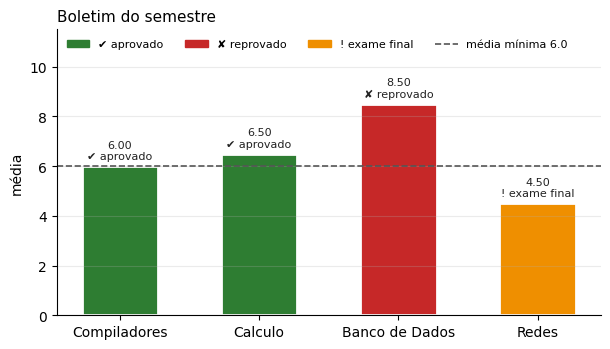

In [60]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

COR_SITUACAO = {"aprovado": "#2e7d32", "exame": "#ef8f00", "reprovado": "#c62828", "em curso": "#78909c"}
ICONE = {"aprovado": "✔ aprovado", "exame": "! exame final", "reprovado": "✘ reprovado", "em curso": "em curso"}

def grafico_notas(vm, titulo="Média por disciplina"):
    if not vm.disciplinas:
        print("(nenhuma nota lançada — nada para desenhar)")
        return
    nomes = list(vm.disciplinas)
    medias = [mean(vm.disciplinas[d]["notas"]) for d in nomes]
    situacoes = [vm.disciplinas[d]["situacao"] for d in nomes]
    fig, ax = plt.subplots(figsize=(max(5, 1.6 * len(nomes)), 3.6))
    ax.bar(nomes, medias, width=0.55, color=[COR_SITUACAO[s] for s in situacoes], edgecolor="white", linewidth=2)
    corte = ax.axhline(6.0, ls="--", lw=1.2, color="#555555", label="média mínima 6.0")
    for x, (m, s) in enumerate(zip(medias, situacoes)):
        ax.text(x, m + 0.2, f"{m:.2f}\n{ICONE[s]}", ha="center", va="bottom", fontsize=8, color="#222222")
    ax.set_ylim(0, 11.5); ax.set_ylabel("média")
    ax.set_title(titulo, fontsize=11, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25)
    presentes = list(dict.fromkeys(situacoes))
    ax.legend(handles=[Patch(color=COR_SITUACAO[s], label=ICONE[s]) for s in presentes] + [corte],
              loc="upper left", fontsize=8, frameon=False, ncols=len(presentes) + 1)
    plt.tight_layout()
    plt.show()

PROG_SEMESTRE = """// Semestre inteiro: quatro disciplinas, um boletim
decimal media = 7.5 * 0.4 + 5.0 * 0.6;
lancar "Compiladores", media;
se media >= 6.0 { aprovar "Compiladores"; } senao { agendar_exame "Compiladores", 3; }

decimal nota = 3.5;
enquanto nota < 6.0 { nota = nota + 0.75; }
lancar "Calculo", nota;
aprovar "Calculo";

lancar "Banco de Dados", (8.0 + 9.0) / 2;
reprovar "Banco de Dados";      // reprovado por falta

lancar "Redes", 4.5;
agendar_exame "Redes", 7;
"""
_semestre = compilar(PROG_SEMESTRE)
assert _semestre.ok, _semestre.erro
mostrar_execucao(_semestre.execucao)
grafico_notas(_semestre.execucao, "Boletim do semestre")

## Passo 8 — Testes automáticos

Cada caso diz **o que deve acontecer**: executar e produzir um trecho de saída, gerar um aviso,
ou falhar numa **fase** específica com um trecho de mensagem. Há também casos que comparam
o programa **otimizado × não otimizado**.

In [61]:
CASOS = [
    # ---------- programas válidos ----------
    ("válido · média ponderada (se/senao)",      PROG_MEDIA,       "ok", "Compiladores: APROVADO"),
    ("válido · recuperação (enquanto)",          PROG_RECUPERACAO, "ok", "Semana 4: nota 6.50"),
    ("válido · boletim (senao se)",              PROG_BOLETIM,     "ok", "Redes: exame final em 7"),
    ("válido · turma com pesos fixos",           PROG_TURMA,       "ok", "Aluno 3: média 8.60"),
    ("válido · escopo de bloco e sombreamento",  PROG_ESCOPO,      "ok", "fora do bloco: 8.00"),
    ("válido · precedência de operadores",       "mostrar 2 + 3 * 4;\nmostrar (2 + 3) * 4;\nmostrar 7 / 2;\nmostrar -2 * -3 > 5 e nao falso;",
                                                                   "ok", "14\n20\n3\nverdadeiro"),
    # ---------- léxico ----------
    ("léxico · acento em nome de variável",      "decimal média = 7.0;",             "léxico", "acento"),
    ("léxico · texto sem fechar aspas",          'lancar "Redes, 7.0;',              "léxico", "aspas de fechamento"),
    ("léxico · '&&' em vez de 'e'",              "logico ok = verdadeiro && falso;", "léxico", "palavra 'e'"),
    # ---------- sintático ----------
    ("sintático · faltou ';'",                   "decimal a = 1.0\nmostrar a;",      "sintático", "termina com ';'"),
    ("sintático · vírgula decimal",              "decimal nota = 7,5;",              "sintático", "usam ponto"),
    ("sintático · bloco sem '}'",                'se verdadeiro { mostrar 1;',       "sintático", "não foi fechado"),
    ("sintático · '=' numa comparação",          'decimal m = 7.0;\nse m = 6.0 { mostrar m; }', "sintático", "'=='"),
    # ---------- semântico ----------
    ("semântico · não declarada + sugestão",     'decimal media = 7.0;\nmostrar meda;', "semântico", "Você quis dizer 'media'"),
    ("semântico · fora do escopo de bloco",      'se verdadeiro { inteiro x = 1; }\nmostrar x;', "semântico", "escopo de bloco"),
    ("semântico · tipo incompatível",            'inteiro faltas = 2.5;\nmostrar faltas;', "semântico", "tipo incompatível"),
    ("semântico · REGRA nota fora de 0..10",     'lancar "BD", -1.0;',               "semântico", "fora do intervalo"),
    ("semântico · REGRA disciplina sem nota",    'aprovar "Redes";',                 "semântico", "ainda não tem nota"),
    # ---------- avisos ----------
    ("aviso · pesos não somam 1.0",              'decimal a = 8.0;\ndecimal b = 6.0;\ndecimal m = a * 0.5 + b * 0.3;\nlancar "X", m;',
                                                                   "aviso", "somam 0.80"),
    ("aviso · variável nunca usada",             'inteiro sobra = 1;\nmostrar "oi";', "aviso", "nunca usada"),
    # ---------- execução ----------
    ("execução · divisão por zero",              'inteiro z = 0;\ninteiro x = 10 / z;\nmostrar x;', "execução", "divisão por zero"),
    ("execução · laço infinito",                 'inteiro i = 0;\nenquanto i < 1 { mostrar i; }', "execução", "laço infinito"),
    ("execução · REGRA aprovar com média < 6",   'decimal m = 5.5;\nlancar "BD", m;\naprovar "BD";', "execução", "não é possível aprovar"),
    ("execução · REGRA nota real > 10",          'decimal n = 9.5;\nn = n * 2;\nlancar "BD", n;', "execução", "fora de 0 a 10"),
    # ---------- otimização ----------
    ("otimização · Exemplo 4 mesma saída",       PROG_TURMA,       "otimiza", None),
    ("otimização · Exemplo 2 mesma saída",       PROG_RECUPERACAO, "otimiza", None),
    # ---------- funções (bônus) ----------
    ("função · parâmetros, retorno e recursão",  PROG_FUNCOES,     "ok", "faltam 2 semana(s)"),
    ("função · coerção inteiro→decimal no argumento",
                                                 'funcao decimal metade(decimal x) { retornar x / 2; }\nmostrar metade(7);',
                                                                   "ok", "3.50"),
    ("função · recursão (fatorial)",             'funcao inteiro fat(inteiro n) {\n  se n <= 1 { retornar 1; }\n  retornar n * fat(n - 1);\n}\nmostrar fat(5);',
                                                                   "ok", "120"),
    ("função · otimizada mesma saída",           PROG_FUNCOES,     "otimiza", None),
    ("função · sintático: dentro de bloco",      'se verdadeiro { funcao inteiro f() { retornar 1; } }', "sintático", "nível principal"),
    ("função · semântico: nº de argumentos",     'funcao decimal dobro(decimal x) { retornar x * 2; }\nmostrar dobro(1.0, 2.0);', "semântico", "espera 1 argumento"),
    ("função · semântico: não declarada + sugestão", 'funcao decimal dobro(decimal x) { retornar x * 2; }\nmostrar dobra(3.0);', "semântico", "Você quis dizer 'dobro'"),
    ("função · semântico: variável de fora",     'decimal b = 1.0;\nfuncao decimal f(decimal n) { retornar n + b; }\nmostrar f(1.0);', "semântico", "Passe 'b' como parâmetro"),
    ("função · semântico: retornar fora",        'retornar 1;',    "semântico", "fora de uma função"),
    ("função · execução: estouro da pilha",      'funcao inteiro f(inteiro n) { retornar f(n + 1); }\nmostrar f(1);', "execução", "pilha de chamadas estourou"),
    ("função · execução: caminho sem retornar",  'funcao texto c(decimal m) { se m >= 6.0 { retornar "A"; } }\nmostrar c(4.0);', "execução", "sem executar nenhum 'retornar'"),
]

def rodar_caso(codigo, esperado, trecho):
    if esperado == "otimiza":
        sem = compilar(codigo, com_otimizacao=False)
        com = compilar(codigo, com_otimizacao=True)
        ok = (sem.ok and com.ok and sem.execucao.saida == com.execucao.saida
              and com.execucao.executadas < sem.execucao.executadas)
        return ok, f"{sem.execucao.executadas} → {com.execucao.executadas} instr." if ok else "saída diferente"
    r = compilar(codigo, limite=5_000)
    if esperado == "ok":
        if not r.ok: return False, f"falhou: {r.erro.mensagem}"
        saida = "\n".join(r.execucao.saida)
        return trecho in saida, "saída ok" if trecho in saida else f"saída: {saida[:60]!r}"
    if esperado == "aviso":
        achou = any(trecho in a for a in r.avisos)
        return r.ok and achou, "aviso emitido" if achou else f"avisos: {r.avisos}"
    if r.ok:
        return False, "deveria ter dado erro"
    ok = r.fase_erro == esperado and trecho in str(r.erro)
    return ok, (f"erro {r.fase_erro} ok" if ok else f"erro {r.fase_erro}: {r.erro.mensagem}")

def rodar_testes(casos=CASOS):
    passou = 0
    fases = Counter()
    print(f"{'':2} {'CASO':<44} {'ESPERADO':<10} DETALHE")
    print("─" * 90)
    for nome, codigo, esperado, trecho in casos:
        try:
            ok, detalhe = rodar_caso(codigo, esperado, trecho)
        except Exception as ex:                      # qualquer exceção não tratada é falha
            ok, detalhe = False, f"EXCEÇÃO {type(ex).__name__}: {ex}"
        passou += ok
        fases[esperado] += 1
        print(f"{'✅' if ok else '❌'} {nome:<44} {esperado:<10} {detalhe}")
    print("─" * 90)
    print(f"{passou}/{len(casos)} casos passaram · por tipo: " + ", ".join(f"{k}={v}" for k, v in fases.items()))
    return passou == len(casos)

TODOS_PASSARAM = rodar_testes()
assert TODOS_PASSARAM, "Há testes falhando!"
assert len(CASOS) >= 12
assert all(f in {c[2] for c in CASOS} for f in ["léxico", "sintático", "semântico", "execução"])
print("\n🎉 Todos os testes passaram!")

   CASO                                         ESPERADO   DETALHE
──────────────────────────────────────────────────────────────────────────────────────────
✅ válido · média ponderada (se/senao)          ok         saída ok
✅ válido · recuperação (enquanto)              ok         saída ok
✅ válido · boletim (senao se)                  ok         saída ok
✅ válido · turma com pesos fixos               ok         saída ok
✅ válido · escopo de bloco e sombreamento      ok         saída ok
✅ válido · precedência de operadores           ok         saída ok
✅ léxico · acento em nome de variável          léxico     erro léxico ok
✅ léxico · texto sem fechar aspas              léxico     erro léxico ok
✅ léxico · '&&' em vez de 'e'                  léxico     erro léxico ok
✅ sintático · faltou ';'                       sintático  erro sintático ok
✅ sintático · vírgula decimal                  sintático  erro sintático ok
✅ sintático · bloco sem '}'                    sintático  erro sintát

## Passo 9 — NotaScript Studio (`ipywidgets`)

O painel abre parado: escolha um exemplo (ou edite o código) e clique em **▶ Compilar e executar**. O painel lateral mostra o **pipeline** fase a fase (✓ passou · ✕ falhou) e as abas trazem cada visão:
**Execução · Tokens · AST · Semântico · TAC · Otimização · Assembly · Gráfico**. Mudar *Otimizar* ou *Registradores* recompila na hora.

In [ ]:
import ipywidgets as w
from IPython.display import display, HTML
import html as _html

EXEMPLOS = {
    "1 · Média ponderada (se/senao)": PROG_MEDIA,
    "2 · Recuperação (enquanto)": PROG_RECUPERACAO,
    "3 · Boletim (senao se)": PROG_BOLETIM,
    "4 · Turma com pesos fixos (otimização)": PROG_TURMA,
    "5 · Escopo de bloco e avisos": PROG_ESCOPO,
    "6 · Semestre inteiro (gráfico)": PROG_SEMESTRE,
    "7 · Funções e recursão (bônus)": PROG_FUNCOES,
}
EXEMPLOS.update({f"Erro semântico · {t}": p for t, p in GALERIA_SEMANTICA})
EXEMPLOS.update({f"Erro de execução · {t}": p for t, p in ERROS_EXECUCAO})
EXEMPLOS["Erro léxico · acento no nome"] = 'decimal média = 7.0;\nmostrar média;'
EXEMPLOS["Erro sintático · faltou ';'"] = 'decimal a1 = 7.5\ndecimal a2 = 5.0;\nmostrar a1;'

# ---------------------------------------------------------------- estilo
CSS = """<style>
.ns-root{font-family:'Segoe UI',Inter,system-ui,sans-serif;color:#1e293b;max-width:1150px}
.ns-hero{background:linear-gradient(135deg,#1e1b4b 0%,#4338ca 60%,#7c3aed 100%);color:#fff;
  border-radius:14px;padding:16px 22px;display:flex;align-items:center;gap:16px}
.ns-hero .logo{font-size:30px;background:rgba(255,255,255,.14);border-radius:12px;width:52px;height:52px;
  display:flex;align-items:center;justify-content:center}
.ns-hero h2{margin:0;font-size:21px;font-weight:700;color:#fff;letter-spacing:.2px}
.ns-hero p{margin:3px 0 0;font-size:12.5px;color:#c7d2fe}
.ns-label{font-size:11px;font-weight:700;letter-spacing:.8px;text-transform:uppercase;color:#64748b;margin:2px 0 6px}
.ns-editor textarea{background:#0f172a!important;color:#e2e8f0!important;
  font-family:'JetBrains Mono','Cascadia Code',Consolas,monospace!important;font-size:13px!important;
  line-height:1.6!important;border:1px solid #1e293b!important;border-radius:12px!important;
  padding:14px 16px!important;caret-color:#a78bfa;resize:vertical}
.ns-side{background:#f8fafc;border:1px solid #e2e8f0;border-radius:12px;padding:12px 14px!important}
.ns-run button,.ns-run{background:linear-gradient(135deg,#4f46e5,#7c3aed)!important;color:#fff!important;
  border:none!important;border-radius:10px!important;font-weight:600!important;font-size:14px!important;
  box-shadow:0 4px 14px rgba(79,70,229,.35)}
.ns-run:hover{filter:brightness(1.08)}
.ns-pipe{display:flex;flex-direction:column;gap:5px}
.ns-step{display:flex;align-items:center;gap:9px;font-size:13px;padding:6px 10px;border-radius:8px;background:#fff;
  border:1px solid #e2e8f0;color:#334155}
.ns-step .dot{width:20px;height:20px;border-radius:50%;display:flex;align-items:center;justify-content:center;
  font-size:11px;font-weight:700;color:#fff;flex:none}
.ns-step.ok .dot{background:#16a34a}.ns-step.err{border-color:#fecaca;background:#fef2f2;color:#991b1b}
.ns-step.err .dot{background:#dc2626}.ns-step.off{color:#94a3b8}.ns-step.off .dot{background:#cbd5e1}
.ns-step .info{margin-left:auto;font-size:11.5px;color:#64748b}
.ns-status{border-radius:10px;padding:10px 12px;font-size:13px;line-height:1.4}
.ns-status.ok{background:#ecfdf5;border:1px solid #a7f3d0;color:#065f46}
.ns-status.err{background:#fef2f2;border:1px solid #fecaca;color:#991b1b}
.ns-kpis{display:grid;grid-template-columns:repeat(auto-fit,minmax(130px,1fr));gap:10px;margin-bottom:14px}
.ns-kpi{background:#fff;border:1px solid #e2e8f0;border-radius:12px;padding:10px 12px;border-top:4px solid var(--c)}
.ns-kpi .v{font-size:22px;font-weight:700;color:#0f172a}.ns-kpi .k{font-size:11.5px;color:#64748b}
.ns-table{width:100%;border-collapse:collapse;font-size:13px;margin-bottom:14px;background:#fff;
  border:1px solid #e2e8f0;border-radius:12px;overflow:hidden}
.ns-table th{background:#f1f5f9;text-align:left;padding:8px 12px;font-size:11px;text-transform:uppercase;
  letter-spacing:.6px;color:#64748b}
.ns-table td{padding:8px 12px;border-top:1px solid #f1f5f9;color:#1e293b}
.ns-bar{height:8px;border-radius:4px;background:#e2e8f0;position:relative;min-width:120px}
.ns-bar span{position:absolute;left:0;top:0;bottom:0;border-radius:4px}
.ns-bar i{position:absolute;left:60%;top:-3px;bottom:-3px;border-left:2px dashed #475569}
.ns-badge{display:inline-block;padding:2px 10px;border-radius:999px;font-size:11.5px;font-weight:600;color:#fff}
.ns-console{background:#0f172a;color:#e2e8f0;border-radius:12px;padding:12px 16px;margin:0 0 14px;
  font-family:'JetBrains Mono','Cascadia Code',Consolas,monospace;font-size:12.5px;line-height:1.7;white-space:pre-wrap}
.ns-warn{background:#fffbeb;border:1px solid #fde68a;color:#92400e;border-radius:10px;padding:9px 12px;
  font-size:12.5px;white-space:pre-wrap;margin-bottom:12px;font-family:Consolas,monospace}
.ns-erro{background:#fff;border:1px solid #fecaca;border-left:5px solid #dc2626;border-radius:12px;
  padding:12px 16px;margin-bottom:12px}
.ns-erro .t{font-weight:700;color:#991b1b;font-size:14px}.ns-erro .loc{color:#64748b;font-size:12px;margin-left:6px}
.ns-erro .m{margin:4px 0 8px;color:#1e293b;font-size:13.5px}
.ns-snip{background:#0f172a;color:#e2e8f0;border-radius:8px;padding:8px 12px;margin:0 0 8px;
  font-family:'JetBrains Mono',Consolas,monospace;font-size:12.5px;white-space:pre}
.ns-snip .ln{color:#64748b}.ns-snip .caret{color:#f87171;font-weight:700}
.ns-dica{background:#eef2ff;color:#3730a3;border-radius:8px;padding:7px 10px;font-size:12.5px}
.ns-out{background:#fff;border:1px solid #e2e8f0;border-radius:0 0 12px 12px;padding:12px 14px;min-height:120px}
.ns-out pre{font-family:'JetBrains Mono','Cascadia Code',Consolas,monospace!important;font-size:12.5px!important}
</style>"""

COR_BADGE = {"aprovado": "#16a34a", "exame": "#d97706", "reprovado": "#dc2626", "em curso": "#64748b"}
esc = _html.escape

# ---------------------------------------------------------------- blocos HTML
def _bloco_erro(e, codigo):
    titulo = f"Erro {e.fase}"
    loc = ""
    if e.linha:
        loc = f"linha {e.linha}" + (f", coluna {e.coluna}" if e.coluna else "")
    h = f"<div class='ns-erro'><span class='t'>✖ {esc(titulo)}</span><span class='loc'>{loc}</span>"
    h += f"<div class='m'>{esc(e.mensagem)}</div>"
    fonte = e.codigo or codigo
    if fonte and e.linha:
        linhas = fonte.split("\n")
        if 1 <= e.linha <= len(linhas):
            h += f"<pre class='ns-snip'><span class='ln'>{e.linha:>3} │</span> {esc(linhas[e.linha - 1])}"
            if e.coluna:
                h += "\n      " + " " * (e.coluna - 1) + "<span class='caret'>^</span>"
            h += "</pre>"
    if e.dica:
        h += f"<div class='ns-dica'>💡 {esc(e.dica)}</div>"
    h += "</div>"
    for o in getattr(e, "outros", []):
        h += _bloco_erro(o, codigo)
    return h

def _html_execucao(r):
    h = ""
    if r.avisos:
        h += "<div class='ns-warn'>" + esc("\n".join(map(str, r.avisos))) + "</div>"
    if not r.ok:
        parcial = getattr(r.erro, "saida_parcial", None)
        if parcial:
            h += "<div class='ns-label'>Saída até o erro</div>"
            corte = len(parcial) - 25
            txt = esc("\n".join(parcial[-25:]))
            if corte > 0:
                txt = f"<span style='color:#64748b'>… {corte} linhas anteriores omitidas</span>\n" + txt
            h += "<div class='ns-console'>" + txt + "</div>"
        return h + _bloco_erro(r.erro, r.codigo)

    vm = r.execucao; e = vm.estatisticas
    kpis = [("Média geral", f"{e.get('media_geral', 0):.2f}", "#4f46e5"),
            ("Aprovações", e.get("aprovacoes", 0), "#16a34a"),
            ("Reprovações", e.get("reprovacoes", 0), "#dc2626"),
            ("Exames", e.get("exames_agendados", 0), "#d97706"),
            ("Taxa de aprovação", f"{e.get('taxa_aprovacao', 0):.1f}%", "#0891b2"),
            ("Instruções", e.get("instrucoes_executadas", 0), "#64748b")]
    if e.get("chamadas_funcao"):
        kpis.append(("Chamadas de função", f"{e['chamadas_funcao']} · pilha {e['profundidade_maxima']}", "#7c3aed"))
    h += "<div class='ns-kpis'>" + "".join(
        f"<div class='ns-kpi' style='--c:{c}'><div class='v'>{v}</div><div class='k'>{k}</div></div>"
        for k, v, c in kpis) + "</div>"

    if vm.disciplinas:
        h += "<div class='ns-label'>Disciplinas</div><table class='ns-table'>"
        h += "<tr><th>Disciplina</th><th>Notas</th><th>Média</th><th style='width:32%'>0 ─ 6 ─ 10</th><th>Situação</th></tr>"
        for d, info in vm.disciplinas.items():
            m = mean(info["notas"]); s = info["situacao"]; c = COR_BADGE.get(s, "#64748b")
            notas = ", ".join(f"{n:.2f}" for n in info["notas"])
            h += (f"<tr><td><b>{esc(d)}</b></td><td>{notas}</td><td><b>{m:.2f}</b></td>"
                  f"<td><div class='ns-bar'><span style='width:{min(m, 10) * 10:.0f}%;background:{c}'></span><i></i></div></td>"
                  f"<td><span class='ns-badge' style='background:{c}'>{esc(s.upper())}</span></td></tr>")
        h += "</table>"

    h += "<div class='ns-label'>Saída do programa</div>"
    h += "<div class='ns-console'>" + (esc("\n".join(vm.saida)) or "<span style='color:#64748b'>(sem saída)</span>") + "</div>"
    return h

FASES = ["Léxico", "Sintático", "Semântico", "TAC", "Otimização", "Execução"]
IDX_ERRO = {"léxico": 0, "sintático": 1, "semântico": 2, "execução": 5}

def _html_lateral(r, otim):
    k = IDX_ERRO.get(r.fase_erro, len(FASES))
    info = {0: f"{len(r.tokens)} tokens" if r.tokens else "",
            2: f"{len(r.semantico.tabela.todos)} símbolos" if r.semantico and k > 2 else "",
            3: f"{len(r.tac)} instr." if r.tac else "",
            4: (f"{len(r.tac)} → {len(r.tac_otimizado)}" if r.tac_otimizado else "") if otim else "desligada",
            5: f"{r.execucao.executadas} passos" if r.execucao else ""}
    h = "<div class='ns-label'>Pipeline</div><div class='ns-pipe'>"
    for i, nome in enumerate(FASES):
        if i == 4 and not otim and i < k:
            cls, dot = "off", "–"
        elif i < k:
            cls, dot = "ok", "✓"
        elif i == k:
            cls, dot = "err", "✕"
        else:
            cls, dot = "off", str(i + 1)
        h += f"<div class='ns-step {cls}'><span class='dot'>{dot}</span>{nome}<span class='info'>{info.get(i, '') if cls != 'err' else 'falhou'}</span></div>"
    h += "</div><div style='height:10px'></div>"
    if r.ok:
        h += (f"<div class='ns-status ok'><b>✔ Compilado e executado</b><br>"
              f"{r.execucao.executadas} instruções executadas</div>")
    else:
        h += f"<div class='ns-status err'><b>✖ Erro {esc(r.fase_erro)}</b><br>{esc(r.erro.mensagem)}</div>"
    return h

# ---------------------------------------------------------------- widgets
seletor = w.Dropdown(options=list(EXEMPLOS), layout=w.Layout(width="100%"))
editor = w.Textarea(value=EXEMPLOS[seletor.value], layout=w.Layout(width="100%", height="300px"))
editor.add_class("ns-editor")
chk_otim = w.Checkbox(value=True, description="Otimizar o TAC", indent=False)
regs = w.IntSlider(value=3, min=2, max=6, description="Registradores", style={"description_width": "initial"},
                   layout=w.Layout(width="100%"))
botao = w.Button(description="▶  Compilar e executar", layout=w.Layout(width="100%", height="42px"))
botao.add_class("ns-run")
lateral = w.HTML()

VISOES = ["▶ Execução", "Tokens", "AST", "Semântico", "TAC", "Otimização", "Assembly", "Gráfico"]
saidas = {v: w.Output() for v in VISOES}
for o in saidas.values():
    o.add_class("ns-out")
abas = w.Tab(children=[saidas[v] for v in VISOES])
for k, v in enumerate(VISOES):
    abas.set_title(k, v)

def _escrever(out, func, codigo):
    with out:
        try:
            func()
        except ErroCompilacao as e:
            display(HTML(_bloco_erro(e, codigo)))

def atualizar(_=None):
    for o in saidas.values():
        o.clear_output()
    codigo = editor.value
    r = compilar(codigo, com_otimizacao=chk_otim.value, limite=20_000)
    lateral.value = _html_lateral(r, chk_otim.value)
    sem_fase = lambda: display(HTML(_bloco_erro(r.erro, codigo)))

    def execucao():
        display(HTML(_html_execucao(r)))
    def tokens():
        tabela_tokens(codigo)
    def ast():
        if r.ast is None: return sem_fase()
        mostrar_ast(r.ast)
    def semantico():
        if r.semantico is None: return sem_fase()
        r.semantico.tabela.mostrar()
        print("\nAvisos:", *(r.avisos or ["nenhum"]), sep="\n")
        if r.fase_erro == "semântico": sem_fase()
    def tac():
        if r.tac is None: return sem_fase()
        listar_tac(r.tac, f"TAC ({len(r.tac)} instruções)")
    def otimizacao():
        if r.tac is None: return sem_fase()
        if r.fase_erro == "execução" or not chk_otim.value:
            otim, tec = otimizar(r.tac, r.tipos)
        else:
            otim, tec = r.tac_otimizado, r.tecnicas
        antes_depois(r.tac, otim)
        print("\nTécnicas:", ", ".join(f"{k} ×{v}" for k, v in tec.items()) or "nenhuma")
        try:
            a, d = executar_tac(r.tac, 20_000), executar_tac(otim, 20_000)
            print(f"Instruções executadas: {a.executadas} → {d.executadas} · mesma saída: {'✅' if a.saida == d.saida else '❌'}")
        except ErroExecucao as e:
            print("(execução falhou, sem comparação)", e.mensagem)
    def assembly():
        if r.tac is None: return sem_fase()
        mostrar_assembly(r.tac_otimizado or r.tac, regs.value)
    def grafico():
        if r.ok: grafico_notas(r.execucao)
        else: display(HTML("<div class='ns-warn'>Sem gráfico: o programa não executou até o fim.</div>"))

    for nome, f in zip(VISOES, [execucao, tokens, ast, semantico, tac, otimizacao, assembly, grafico]):
        _escrever(saidas[nome], f, codigo)

def _trocar_exemplo(mudanca):
    editor.value = EXEMPLOS[mudanca["new"]]
    abas.selected_index = 0
    atualizar()

seletor.observe(_trocar_exemplo, names="value")
chk_otim.observe(lambda _: atualizar(), names="value")
regs.observe(lambda _: atualizar(), names="value")
botao.on_click(atualizar)

cabecalho = w.HTML(CSS + """
<div class='ns-hero'><div class='logo'>🎓</div><div>
  <h2>NotaScript Studio</h2>
  <p>Léxico → Sintático → Semântico → TAC → Otimização → VM · escreva, compile e veja cada fase</p>
</div></div>""")

col_editor = w.VBox([w.HTML("<div class='ns-label'>Exemplo</div>"), seletor,
                     w.HTML("<div class='ns-label' style='margin-top:10px'>Código-fonte</div>"), editor],
                    layout=w.Layout(flex="3 1 420px", min_width="0", margin="0 14px 0 0"))
col_lateral = w.VBox([botao, w.HTML("<div style='height:6px'></div>"), chk_otim, regs,
                      w.HTML("<div style='height:4px'></div>"), lateral],
                     layout=w.Layout(flex="2 1 260px", min_width="0"))
col_lateral.add_class("ns-side")

studio = w.VBox([
    cabecalho,
    w.Box([col_editor, col_lateral], layout=w.Layout(display="flex", flex_flow="row wrap",
                                                      align_items="stretch", margin="12px 0")),
    abas,
])
studio.add_class("ns-root")
display(studio)
# O painel abre sem compilar sozinho (evita travar o VS Code ao desenhar os widgets):
# escolha um exemplo e clique em ▶ Compilar e executar.
lateral.value = ("<div class='ns-status ok'><b>Pronto.</b><br>"
                 "Escolha um exemplo e clique em <b>▶ Compilar e executar</b>.</div>")